In [1]:
import os
import pandas as pd

CSV_YOLU = "data/seeds.csv"
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/wheat-seeds.csv"
SUTUNLAR = ["Alan", "Cevre", "Kompaktlik", "TaneUzunlugu", "TaneGenisligi", "AsimetriKatsayisi", "OlukUzunlugu", "Cesit"]

if not os.path.exists(CSV_YOLU):
    os.makedirs("data", exist_ok=True)
    ham = pd.read_csv(URL, header=None, names=SUTUNLAR)
    ham["Cesit"] = ham["Cesit"].map({1: "Kama", 2: "Rosa", 3: "Kanada"})
    ham.to_csv(CSV_YOLU, index=False)
    print("Veri seti indirildi ve CSV olarak kaydedildi.")
else:
    print("Veri seti mevcut:", CSV_YOLU)

Veri seti mevcut: data/seeds.csv


In [2]:
import time
import warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns
from scipy import stats

from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV,
                                     cross_validate, cross_val_predict, learning_curve, validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.inspection import permutation_importance
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score,
                             f1_score, precision_recall_fscore_support, roc_auc_score, roc_curve,
                             precision_recall_curve, average_precision_score, matthews_corrcoef,
                             cohen_kappa_score, log_loss)

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid", palette="Set2")
%matplotlib inline

df = pd.read_csv(CSV_YOLU)
print("Veri seti başarıyla yüklendi.")
df.head(10)

Veri seti başarıyla yüklendi.


,Alan,Cevre,Kompaktlik,TaneUzunlugu,TaneGenisligi,AsimetriKatsayisi,OlukUzunlugu,Cesit
0,15.2600,14.8400,0.8710,5.7630,3.3120,2.2210,5.2200,Kama
1,14.8800,14.5700,0.8811,5.5540,3.3330,1.0180,4.9560,Kama
2,14.2900,14.0900,0.9050,5.2910,3.3370,2.6990,4.8250,Kama
3,13.8400,13.9400,0.8955,5.3240,3.3790,2.2590,4.8050,Kama
4,16.1400,14.9900,0.9034,5.6580,3.5620,1.3550,5.1750,Kama
5,14.3800,14.2100,0.8951,5.3860,3.3120,2.4620,4.9560,Kama
6,14.6900,14.4900,0.8799,5.5630,3.2590,3.5860,5.2190,Kama
7,14.1100,14.1000,0.8911,5.4200,3.3020,2.7000,5.0000,Kama
8,16.6300,15.4600,0.8747,6.0530,3.4650,2.0400,5.8770,Kama
9,16.4400,15.2500,0.8880,5.8840,3.5050,1.9690,5.5330,Kama


In [3]:
df.sample(5, random_state=1)

,Alan,Cevre,Kompaktlik,TaneUzunlugu,TaneGenisligi,AsimetriKatsayisi,OlukUzunlugu,Cesit
44,15.1100,14.5400,0.8986,5.5790,3.4620,3.1280,5.1800,Kama
188,11.2300,12.8200,0.8594,5.0890,2.8210,7.5240,4.9570,Kanada
51,15.7800,14.9100,0.8923,5.6740,3.4340,5.5930,5.1360,Kama
204,12.3700,13.4700,0.8567,5.2040,2.9600,3.9190,5.0010,Kanada
35,16.1200,15.0000,0.9000,5.7090,3.4850,2.2700,5.4430,Kama


In [4]:
HEDEF = "Cesit"
OZELLIKLER = [k for k in df.columns if k != HEDEF]
SINIFLAR = ["Kama", "Rosa", "Kanada"]
RENK = {"Kama": "#E69F00", "Rosa": "#CC3D7A", "Kanada": "#2A7AB0"}

print(f"Gözlem sayısı           : {df.shape[0]}")
print(f"Değişken sayısı         : {df.shape[1]} ({len(OZELLIKLER)} özellik + hedef)")
print(f"Eksik değer             : {df.isna().sum().sum()}")
print(f"Tekrarlanan satır sayısı: {df.duplicated().sum()}")
print()
df.info()

Gözlem sayısı           : 210
Değişken sayısı         : 8 (7 özellik + hedef)
Eksik değer             : 0
Tekrarlanan satır sayısı: 0

<class 'pandas.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Alan               210 non-null    float64
 1   Cevre              210 non-null    float64
 2   Kompaktlik         210 non-null    float64
 3   TaneUzunlugu       210 non-null    float64
 4   TaneGenisligi      210 non-null    float64
 5   AsimetriKatsayisi  210 non-null    float64
 6   OlukUzunlugu       210 non-null    float64
 7   Cesit              210 non-null    str    
dtypes: float64(7), str(1)
memory usage: 13.3 KB


,Frekans,Oran (%)
Cesit,,
Kama,70,33.3333
Rosa,70,33.3333
Kanada,70,33.3333


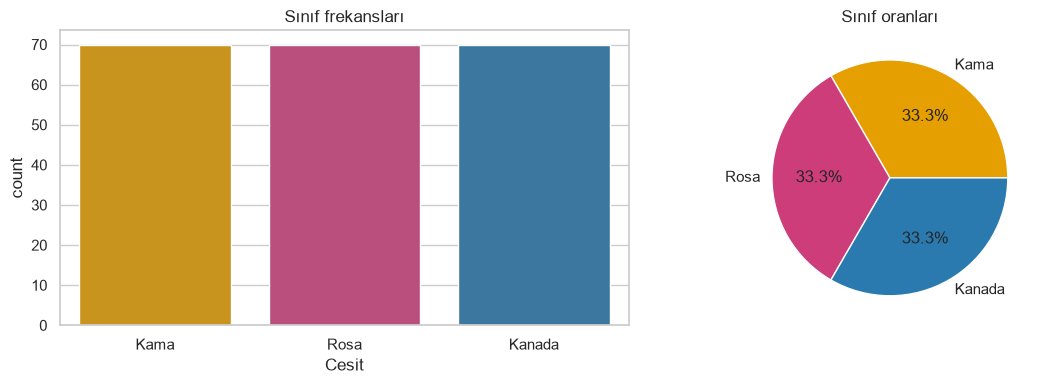

In [5]:
dagilim = pd.DataFrame({"Frekans": df[HEDEF].value_counts().reindex(SINIFLAR),
                        "Oran (%)": df[HEDEF].value_counts(normalize=True).reindex(SINIFLAR) * 100})
display(dagilim)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x=HEDEF, order=SINIFLAR, hue=HEDEF, palette=RENK, ax=axes[0], legend=False)
axes[0].set_title("Sınıf frekansları")
axes[1].pie(dagilim["Frekans"], labels=SINIFLAR, autopct="%1.1f%%", colors=[RENK[s] for s in SINIFLAR])
axes[1].set_title("Sınıf oranları")
plt.tight_layout()
plt.show()

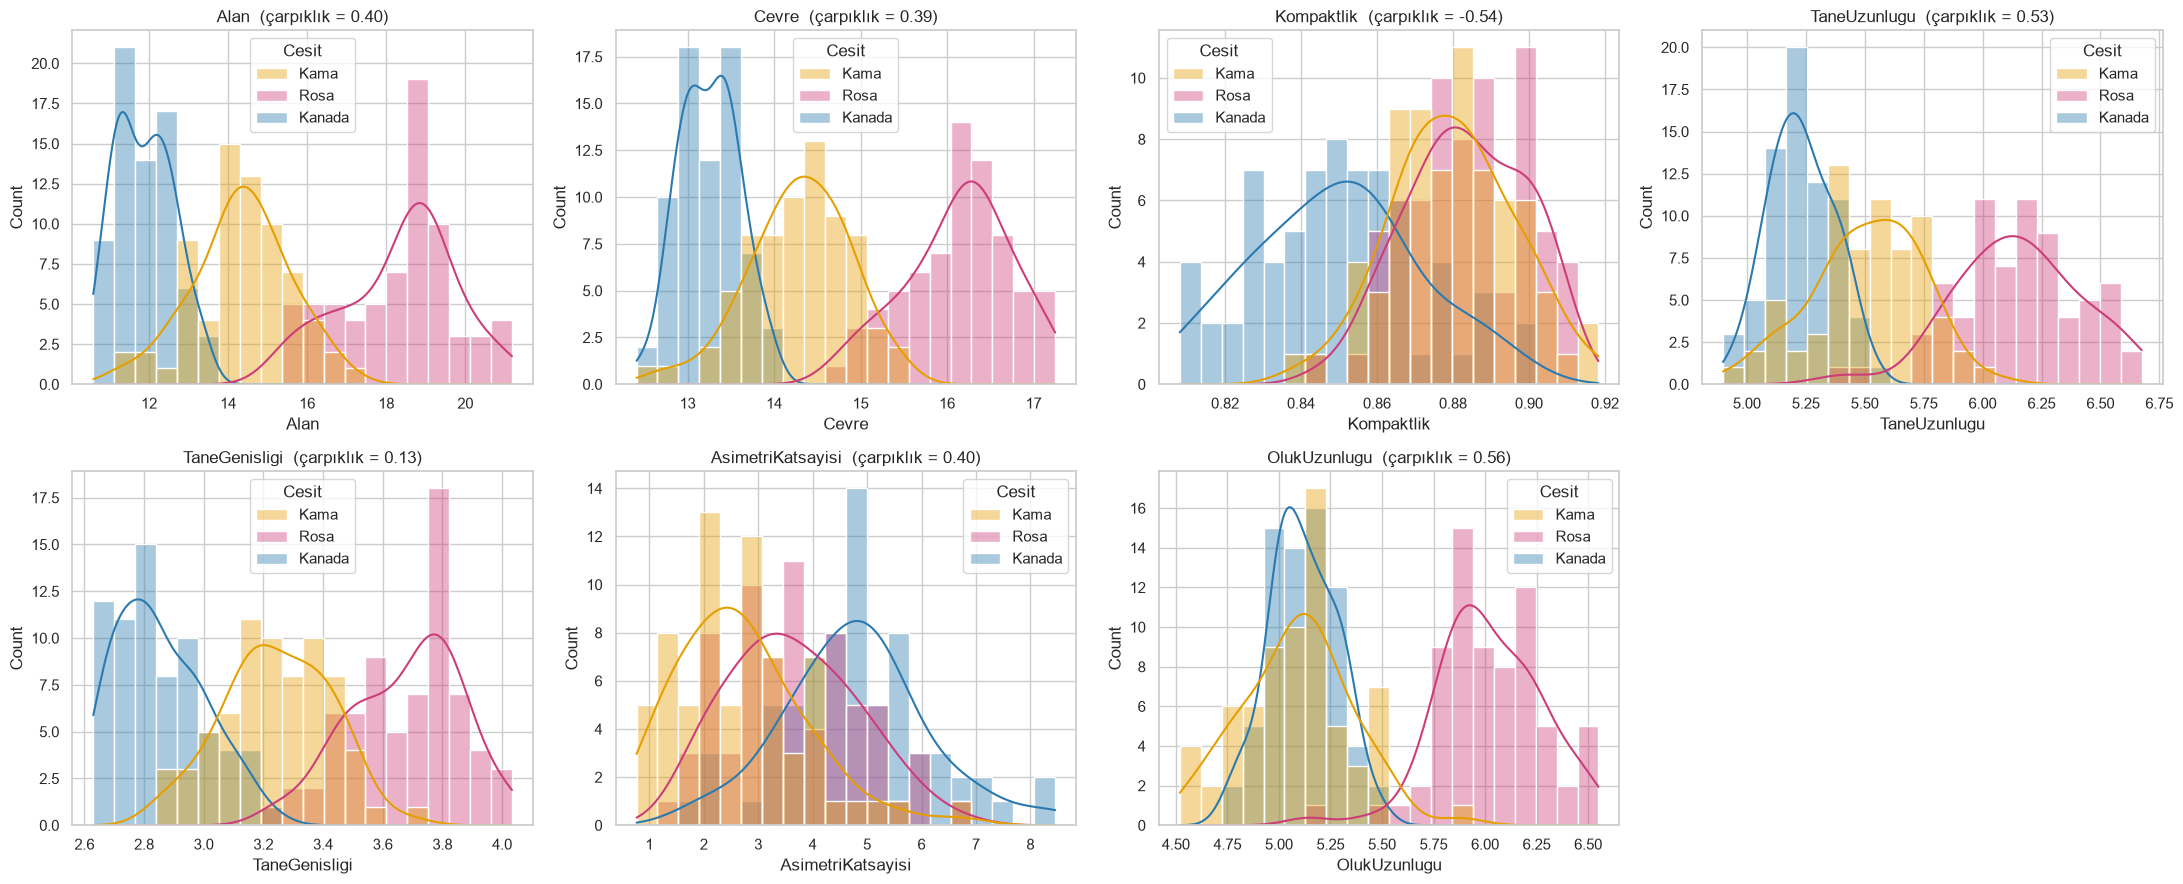

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(22, 9))
for ax, kol in zip(axes.flat, OZELLIKLER):
    sns.histplot(data=df, x=kol, hue=HEDEF, hue_order=SINIFLAR, kde=True, palette=RENK, bins=20, ax=ax, alpha=0.4)
    ax.set_title(f"{kol}  (çarpıklık = {df[kol].skew():.2f})")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

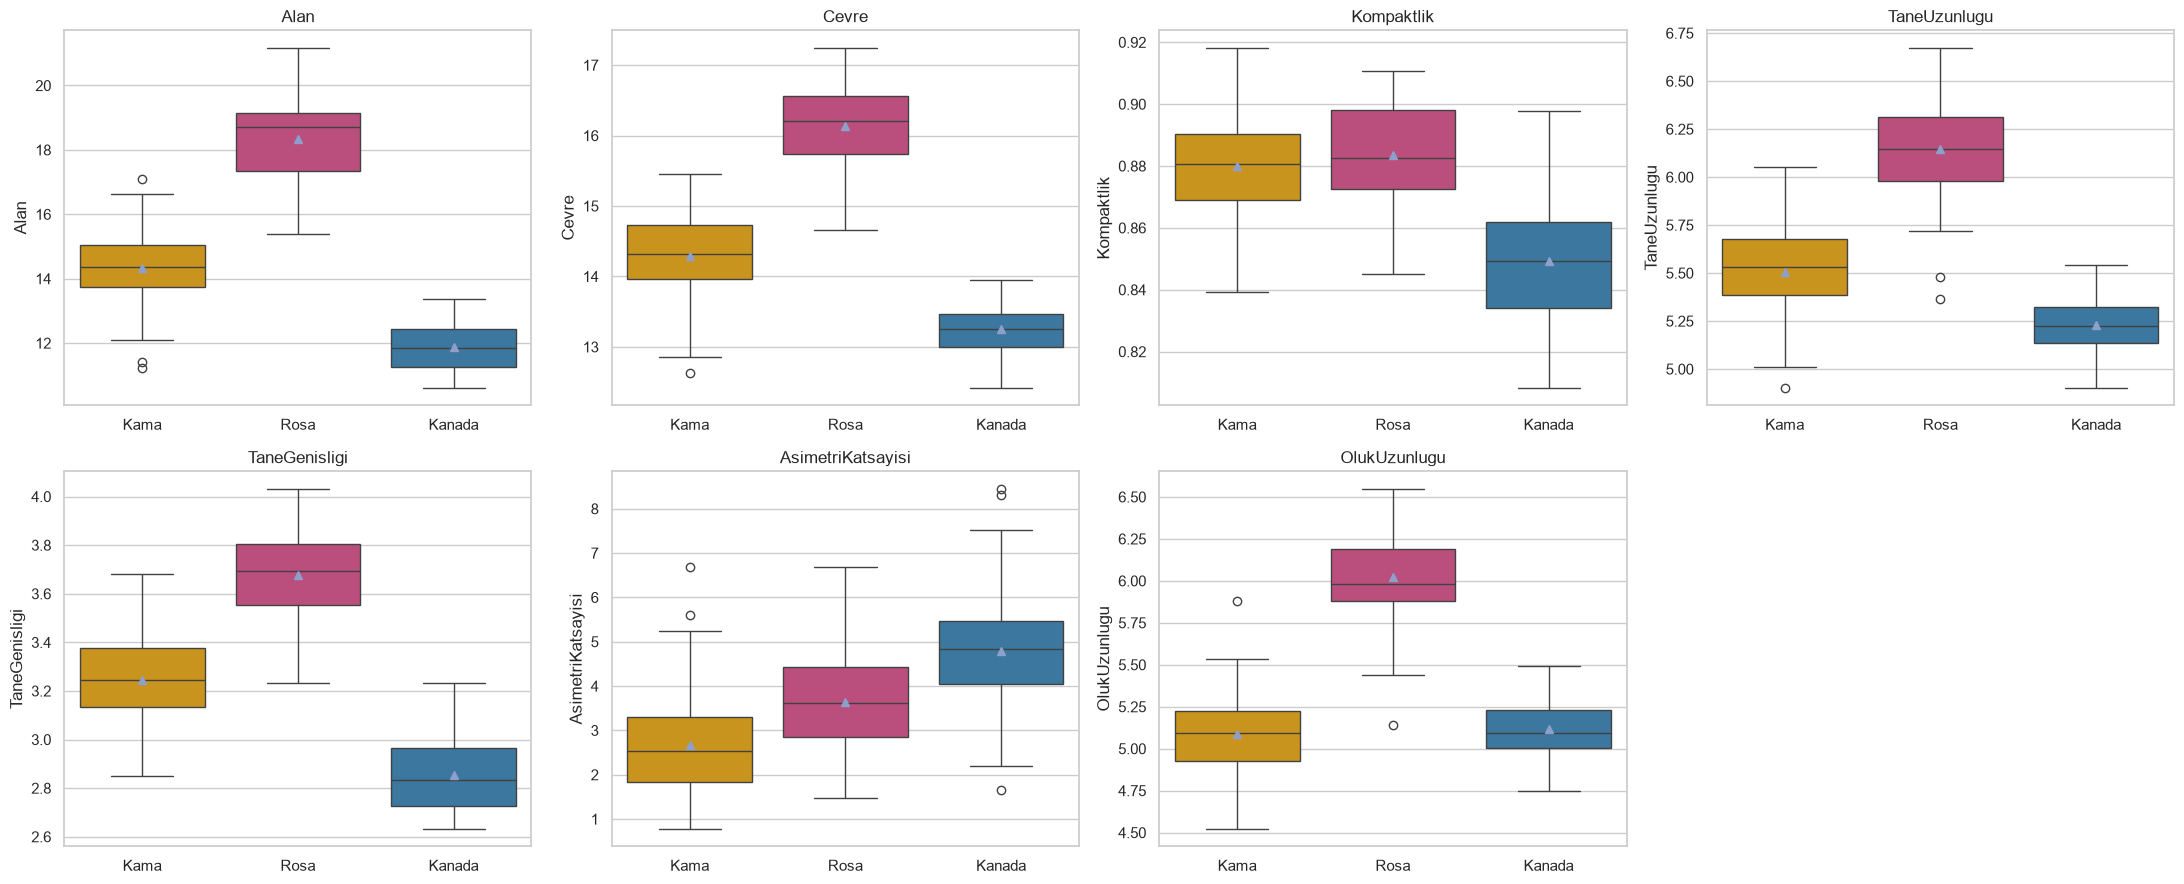

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(22, 9))
for ax, kol in zip(axes.flat, OZELLIKLER):
    sns.boxplot(data=df, x=HEDEF, y=kol, order=SINIFLAR, hue=HEDEF, palette=RENK, ax=ax, legend=False, showmeans=True)
    ax.set_xlabel("")
    ax.set_title(kol)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

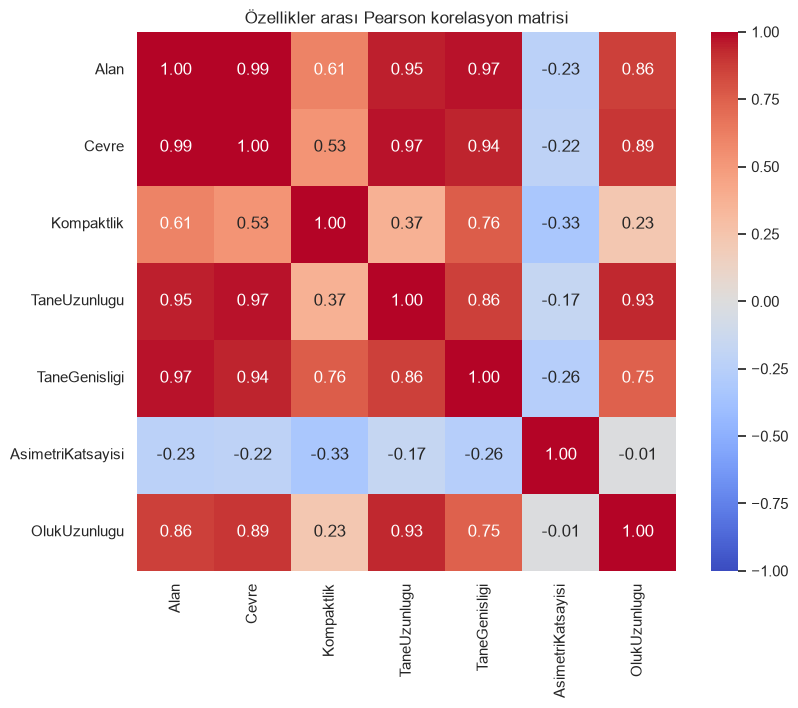

In [8]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[OZELLIKLER].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Özellikler arası Pearson korelasyon matrisi")
plt.show()

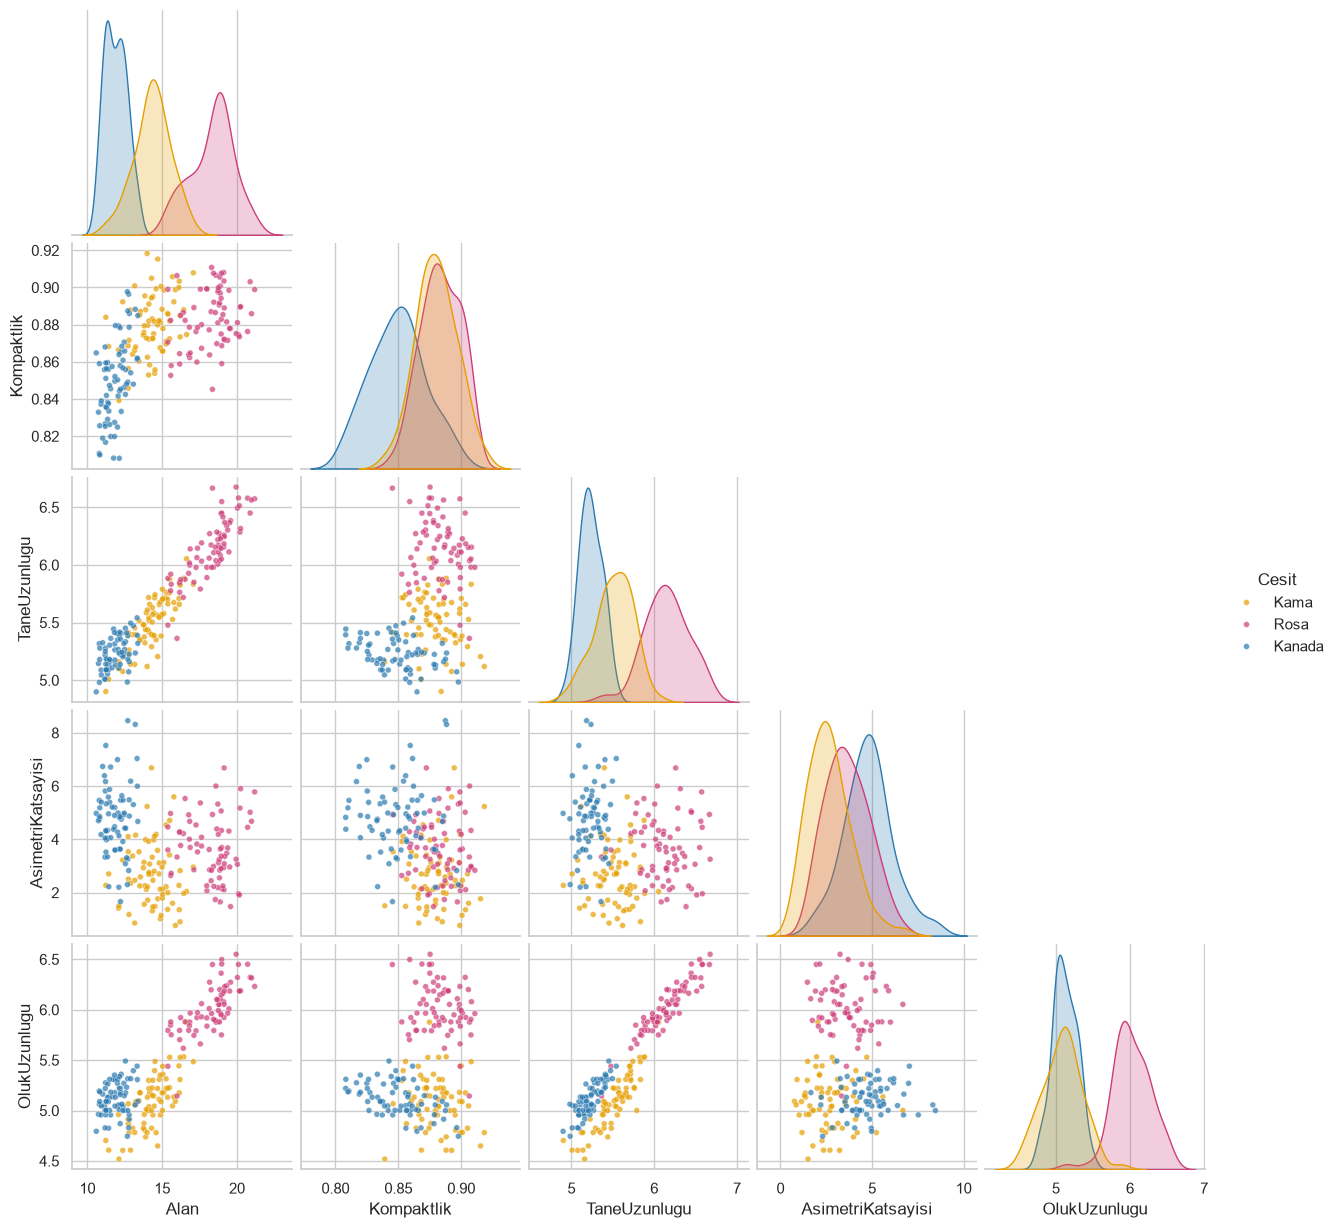

In [9]:
sns.pairplot(df, vars=["Alan", "Kompaktlik", "TaneUzunlugu", "AsimetriKatsayisi", "OlukUzunlugu"], hue=HEDEF,
             hue_order=SINIFLAR, palette=RENK, corner=True, plot_kws={"s": 18, "alpha": 0.7})
plt.show()

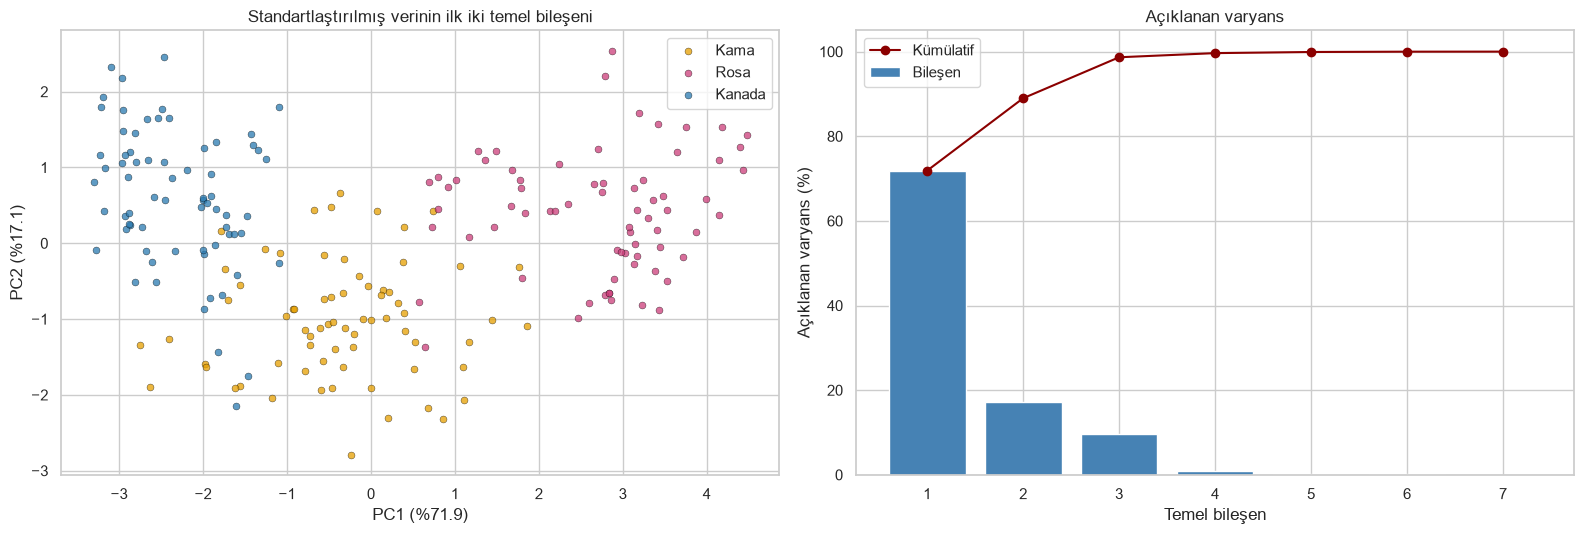

,PC1 yükü,PC2 yükü
Alan,0.4445,0.0266
Cevre,0.4416,0.0840
Kompaktlik,0.2770,-0.5292
TaneUzunlugu,0.4236,0.2060
TaneGenisligi,0.4328,-0.1167
AsimetriKatsayisi,-0.1187,0.7169
OlukUzunlugu,0.3872,0.3772


In [10]:
Z = StandardScaler().fit_transform(df[OZELLIKLER])
pca_eda = PCA().fit(Z)
P = pca_eda.transform(Z)[:, :2]

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for s in SINIFLAR:
    m = df[HEDEF] == s
    axes[0].scatter(P[m, 0], P[m, 1], s=25, alpha=0.75, color=RENK[s], label=s, edgecolor="k", linewidth=0.3)
ao = pca_eda.explained_variance_ratio_
axes[0].set_xlabel(f"PC1 (%{ao[0]*100:.1f})")
axes[0].set_ylabel(f"PC2 (%{ao[1]*100:.1f})")
axes[0].set_title("Standartlaştırılmış verinin ilk iki temel bileşeni")
axes[0].legend()
axes[1].bar(range(1, 8), ao * 100, color="steelblue", label="Bileşen")
axes[1].plot(range(1, 8), np.cumsum(ao) * 100, "o-", color="darkred", label="Kümülatif")
axes[1].set_xlabel("Temel bileşen")
axes[1].set_ylabel("Açıklanan varyans (%)")
axes[1].set_title("Açıklanan varyans")
axes[1].legend()
plt.tight_layout()
plt.show()
pd.DataFrame(pca_eda.components_[:2].T, index=OZELLIKLER, columns=["PC1 yükü", "PC2 yükü"])

In [11]:
df[OZELLIKLER].describe().T

,count,mean,std,min,25%,50%,75%,max
Alan,210.0000,14.8475,2.9097,10.5900,12.2700,14.3550,17.3050,21.1800
Cevre,210.0000,14.5593,1.3060,12.4100,13.4500,14.3200,15.7150,17.2500
Kompaktlik,210.0000,0.8710,0.0236,0.8081,0.8569,0.8735,0.8878,0.9183
TaneUzunlugu,210.0000,5.6285,0.4431,4.8990,5.2622,5.5235,5.9798,6.6750
TaneGenisligi,210.0000,3.2586,0.3777,2.6300,2.9440,3.2370,3.5617,4.0330
AsimetriKatsayisi,210.0000,3.7002,1.5036,0.7651,2.5615,3.5990,4.7687,8.4560
OlukUzunlugu,210.0000,5.4081,0.4915,4.5190,5.0450,5.2230,5.8770,6.5500


In [12]:
def aciklayici_tablo(d):
    satirlar = {}
    for kol in d.columns:
        s = d[kol].dropna()
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        satirlar[kol] = {
            "n": s.count(),
            "Ortalama": s.mean(),
            "Medyan": s.median(),
            "Mod": s.mode().iloc[0],
            "Std. Sapma": s.std(),
            "Varyans": s.var(),
            "Değişim Kats. (%)": s.std() / s.mean() * 100,
            "Std. Hata": s.sem(),
            "Minimum": s.min(),
            "Q1": q1,
            "Q3": q3,
            "Maksimum": s.max(),
            "Açıklık": s.max() - s.min(),
            "IQR": iqr,
            "Çarpıklık": s.skew(),
            "Basıklık": s.kurt(),
            "Shapiro-Wilk p": stats.shapiro(s).pvalue,
            "Aykırı (1.5·IQR)": int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
        }
    return pd.DataFrame(satirlar).T

aciklayici_tablo(df[OZELLIKLER])

,n,Ortalama,Medyan,Mod,Std. Sapma,Varyans,Değişim Kats. (%),Std. Hata,Minimum,Q1,Q3,Maksimum,Açıklık,IQR,Çarpıklık,Basıklık,Shapiro-Wilk p,Aykırı (1.5·IQR)
Alan,210.0000,14.8475,14.3550,11.2300,2.9097,8.4664,19.5972,0.2008,10.5900,12.2700,17.3050,21.1800,10.5900,5.0350,0.3999,-1.0843,0.0000,0.0000
Cevre,210.0000,14.5593,14.3200,13.4700,1.3060,1.7055,8.9699,0.0901,12.4100,13.4500,15.7150,17.2500,4.8400,2.2650,0.3866,-1.1067,0.0000,0.0000
Kompaktlik,210.0000,0.8710,0.8735,0.8823,0.0236,0.0006,2.7129,0.0016,0.8081,0.8569,0.8878,0.9183,0.1102,0.0309,-0.5380,-0.1403,0.0005,3.0000
TaneUzunlugu,210.0000,5.6285,5.5235,5.2360,0.4431,0.1963,7.8717,0.0306,4.8990,5.2622,5.9798,6.6750,1.7760,0.7175,0.5255,-0.7856,0.0000,0.0000
TaneGenisligi,210.0000,3.2586,3.2370,3.0260,0.3777,0.1427,11.5913,0.0261,2.6300,2.9440,3.5617,4.0330,1.4030,0.6178,0.1344,-1.0977,0.0000,0.0000
AsimetriKatsayisi,210.0000,3.7002,3.5990,2.1290,1.5036,2.2607,40.6345,0.1038,0.7651,2.5615,4.7687,8.4560,7.6909,2.2072,0.4017,-0.0666,0.0154,2.0000
OlukUzunlugu,210.0000,5.4081,5.2230,5.0010,0.4915,0.2416,9.0879,0.0339,4.5190,5.0450,5.8770,6.5500,2.0310,0.8320,0.5619,-0.8408,0.0000,0.0000


In [13]:
ort = df.groupby(HEDEF)[OZELLIKLER].mean().T[SINIFLAR].add_suffix(" – ort.")
sapma = df.groupby(HEDEF)[OZELLIKLER].std().T[SINIFLAR].add_suffix(" – std")
ayirt = []
for kol in OZELLIKLER:
    gruplar = [df.loc[df[HEDEF] == s, kol] for s in SINIFLAR]
    h, p = stats.kruskal(*gruplar)
    ss_top = ((df[kol] - df[kol].mean()) ** 2).sum()
    ss_ara = sum(len(g) * (g.mean() - df[kol].mean()) ** 2 for g in gruplar)
    ayirt.append({"Özellik": kol, "Kruskal-Wallis H": h, "p-değeri": p, "η²": ss_ara / ss_top})
ayirt = pd.DataFrame(ayirt).set_index("Özellik")
pd.concat([ort, sapma, ayirt], axis=1).sort_values("η²", ascending=False)

,Kama – ort.,Rosa – ort.,Kanada – ort.,Kama – std,Rosa – std,Kanada – std,Kruskal-Wallis H,p-değeri,η²
Alan,14.3344,18.3343,11.8739,1.2157,1.4395,0.7230,174.0015,0.0000,0.8412
Cevre,14.2943,16.1357,13.2479,0.5766,0.6170,0.3402,171.9300,0.0000,0.8396
TaneGenisligi,3.2446,3.6774,2.8538,0.1776,0.1855,0.1475,168.0682,0.0000,0.7970
OlukUzunlugu,5.0872,6.0206,5.1164,0.2637,0.2539,0.1621,134.8567,0.0000,0.7809
TaneUzunlugu,5.5081,6.1480,5.2295,0.2315,0.2682,0.1380,153.3770,0.0000,0.7569
Kompaktlik,0.8801,0.8835,0.8494,0.0162,0.0155,0.0218,82.6546,0.0000,0.4230
AsimetriKatsayisi,2.6674,3.6448,4.7884,1.1739,1.1819,1.3365,72.4626,0.0000,0.3339


In [14]:
X = df[OZELLIKLER]
y = df[HEDEF]
X_egitim, X_test, y_egitim, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

pd.DataFrame({"Gözlem": [len(y_egitim), len(y_test)],
              **{s: [(y_egitim == s).sum(), (y_test == s).sum()] for s in SINIFLAR}}, index=["Eğitim", "Test"])

,Gözlem,Kama,Rosa,Kanada
Eğitim,147,49,49,49
Test,63,21,21,21


In [15]:
ann_pipe = Pipeline([("olcek", StandardScaler()),
                     ("ann", MLPClassifier(solver="adam", max_iter=3000, random_state=42))])
izgara = {"ann__hidden_layer_sizes": [(5,), (10,), (20,), (50,), (10, 5), (20, 10)],
          "ann__activation": ["relu", "tanh", "logistic"],
          "ann__alpha": [0.0001, 0.001, 0.01, 0.1, 1.0]}

t0 = time.perf_counter()
arama = GridSearchCV(ann_pipe, izgara, cv=cv, scoring="accuracy", n_jobs=-1).fit(X_egitim, y_egitim)
print(f"Arama süresi: {time.perf_counter() - t0:.1f} sn")
print("En iyi parametreler:", {k.replace("ann__", ""): v for k, v in arama.best_params_.items()})
print(f"En iyi CV doğruluğu: {arama.best_score_:.4f}")

sonuc = pd.DataFrame(arama.cv_results_)
sonuc["mimari"] = sonuc["param_ann__hidden_layer_sizes"].map(lambda t: "-".join(map(str, t)))
sonuc["aktivasyon"] = sonuc["param_ann__activation"]
sonuc["alpha"] = sonuc["param_ann__alpha"].astype(float)
sonuc.sort_values("rank_test_score")[["mimari", "aktivasyon", "alpha", "mean_test_score", "std_test_score",
                                      "rank_test_score"]].head(10).reset_index(drop=True)

Arama süresi: 26.4 sn
En iyi parametreler: {'activation': 'tanh', 'alpha': 1.0, 'hidden_layer_sizes': (10,)}
En iyi CV doğruluğu: 0.9591


,mimari,aktivasyon,alpha,mean_test_score,std_test_score,rank_test_score
0,10,tanh,1.0000,0.9591,0.0259,1
1,20,tanh,1.0000,0.9591,0.0259,1
2,10,tanh,0.0001,0.9524,0.0274,3
3,20,tanh,0.0001,0.9524,0.0274,3
4,50,tanh,0.0001,0.9524,0.0405,3
5,20,logistic,0.0010,0.9524,0.0274,3
6,10,tanh,0.0010,0.9524,0.0274,3
7,20,tanh,0.0010,0.9524,0.0274,3
8,50,tanh,0.0010,0.9524,0.0405,3
9,10,tanh,0.0100,0.9524,0.0274,3


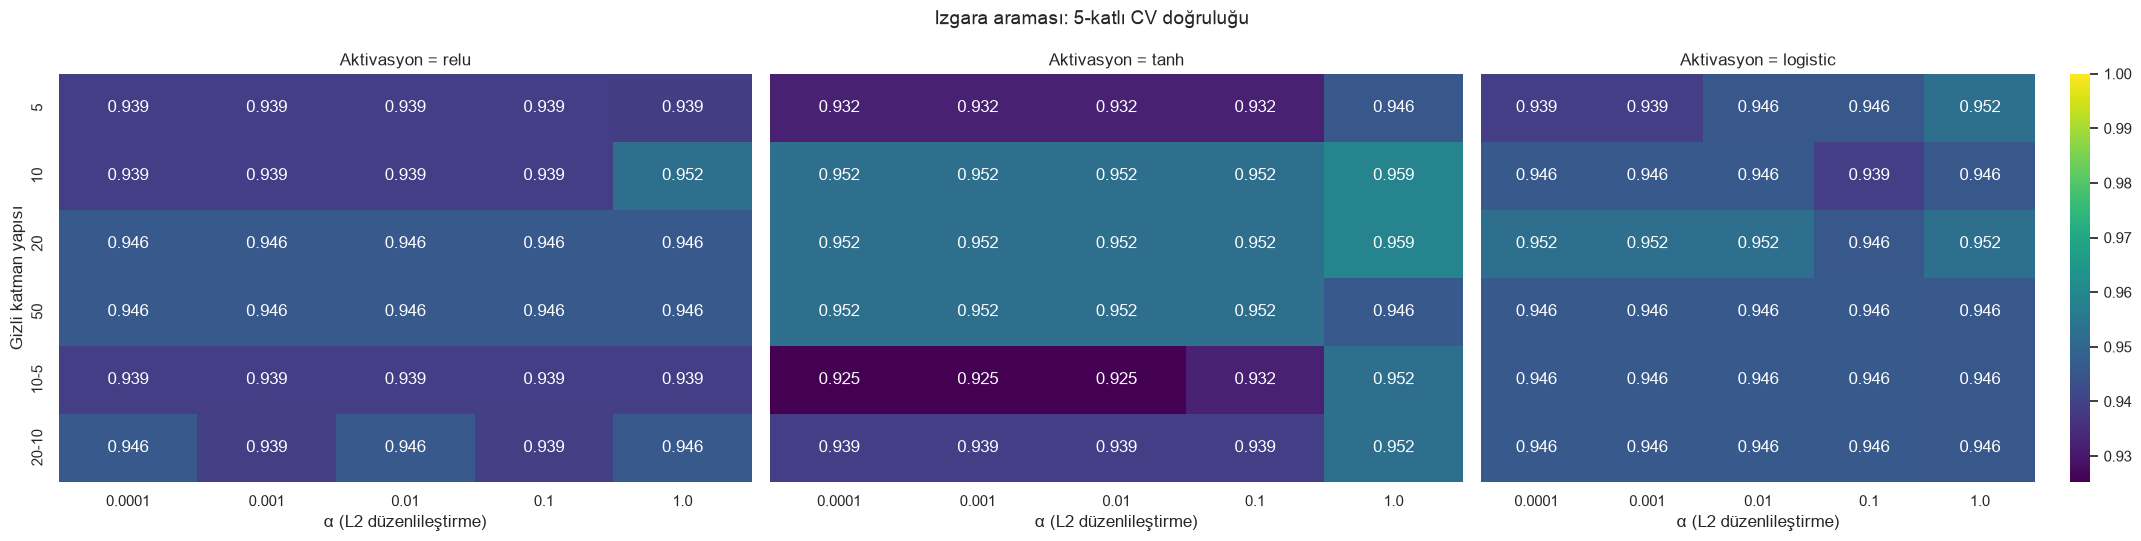

,Ortalama CV doğr.,En iyi,En kötü
Aktivasyon,,,
logistic,0.9461,0.9524,0.9389
relu,0.9423,0.9522,0.9386
tanh,0.9445,0.9591,0.9253


In [16]:
MIMARI_SIRA = ["5", "10", "20", "50", "10-5", "20-10"]
fig, axes = plt.subplots(1, 3, figsize=(22, 5.5), sharey=True)
for ax, akt in zip(axes, ["relu", "tanh", "logistic"]):
    t = sonuc[sonuc["aktivasyon"] == akt].pivot(index="mimari", columns="alpha", values="mean_test_score").loc[MIMARI_SIRA]
    sns.heatmap(t, annot=True, fmt=".3f", cmap="viridis", vmin=sonuc["mean_test_score"].min(), vmax=1, ax=ax,
                cbar=ax is axes[-1])
    ax.set_title(f"Aktivasyon = {akt}")
    ax.set_xlabel("α (L2 düzenlileştirme)")
    ax.set_ylabel("Gizli katman yapısı" if ax is axes[0] else "")
fig.suptitle("Izgara araması: 5-katlı CV doğruluğu", fontsize=14)
plt.tight_layout()
plt.show()

display(sonuc.groupby("aktivasyon")["mean_test_score"].agg(["mean", "max", "min"]).rename_axis("Aktivasyon")
        .rename(columns={"mean": "Ortalama CV doğr.", "max": "En iyi", "min": "En kötü"}))

In [17]:
model = arama.best_estimator_
ann = model.named_steps["ann"]
katmanlar = [ann.n_features_in_, *ann.hidden_layer_sizes, ann.n_outputs_]
param_sayisi = sum(W.size + b.size for W, b in zip(ann.coefs_, ann.intercepts_))

print(f"Katman boyutları        : {' → '.join(map(str, katmanlar))}")
print(f"Gizli katman aktivasyonu: {ann.activation}")
print(f"Çıkış aktivasyonu       : {ann.out_activation_}")
print(f"L2 katsayısı (α)        : {ann.alpha}")
print(f"Toplam parametre sayısı : {param_sayisi} (ağırlık + sapma)")
print(f"Eğitim epok sayısı      : {ann.n_iter_}")
print(f"Son eğitim kaybı        : {ann.loss_:.4f}")
print(f"Sınıf sırası (çıkış)    : {list(ann.classes_)}")

Katman boyutları        : 7 → 10 → 3
Gizli katman aktivasyonu: tanh
Çıkış aktivasyonu       : softmax
L2 katsayısı (α)        : 1.0
Toplam parametre sayısı : 113 (ağırlık + sapma)
Eğitim epok sayısı      : 674
Son eğitim kaybı        : 0.1830
Sınıf sırası (çıkış)    : [np.str_('Kama'), np.str_('Kanada'), np.str_('Rosa')]


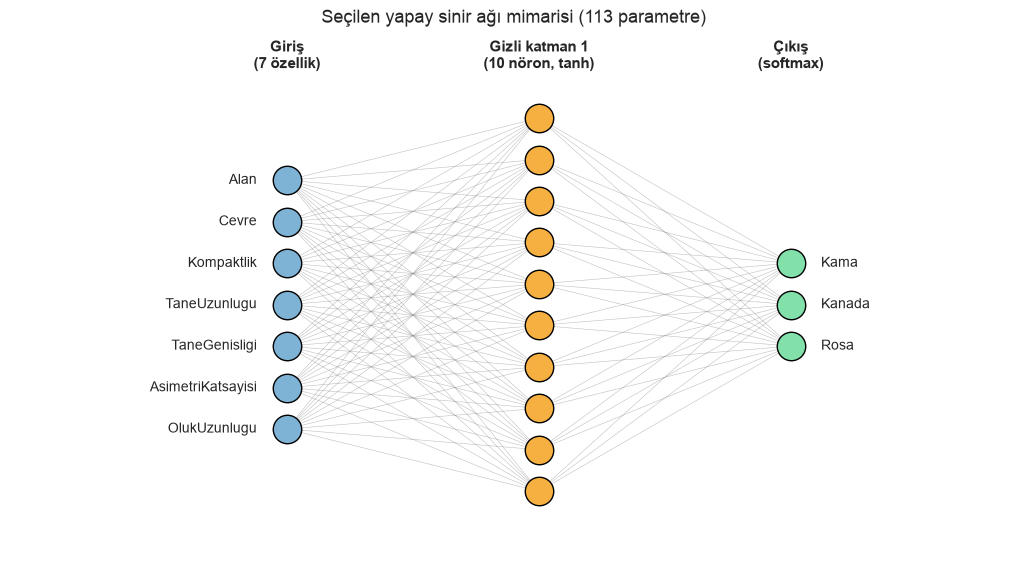

In [18]:
def ag_ciz(katmanlar, adlar_giris, adlar_cikis, ax, en_fazla=12):
    x_ara = 1.0
    konumlar = []
    for li, n in enumerate(katmanlar):
        goster = min(n, en_fazla)
        ys = np.linspace((goster - 1) / 2, -(goster - 1) / 2, goster)
        konumlar.append((li * x_ara, ys, n > en_fazla))
    for (x0, ys0, _), (x1, ys1, _) in zip(konumlar[:-1], konumlar[1:]):
        for a in ys0:
            for b in ys1:
                ax.plot([x0, x1], [a, b], color="gray", lw=0.4, alpha=0.5, zorder=1)
    renkler = ["#7FB3D5"] + ["#F5B041"] * (len(katmanlar) - 2) + ["#82E0AA"]
    for li, ((x, ys, kesik), r) in enumerate(zip(konumlar, renkler)):
        ax.scatter([x] * len(ys), ys, s=420, color=r, edgecolor="k", zorder=3)
        if kesik:
            ax.text(x, ys.min() - 0.9, f"... ({katmanlar[li]} nöron)", ha="center", fontsize=9)
    for yv, ad in zip(konumlar[0][1], adlar_giris):
        ax.text(-0.12, yv, ad, ha="right", va="center", fontsize=10)
    for yv, ad in zip(konumlar[-1][1], adlar_cikis):
        ax.text(konumlar[-1][0] + 0.12, yv, ad, ha="left", va="center", fontsize=10)
    basliklar = ["Giriş\n(7 özellik)"] + [f"Gizli katman {i}\n({n} nöron, {ann.activation})"
                                          for i, n in enumerate(katmanlar[1:-1], 1)] + ["Çıkış\n(softmax)"]
    ust = max(len(k[1]) for k in konumlar) / 2 + 0.6
    for (x, _, _), b in zip(konumlar, basliklar):
        ax.text(x, ust, b, ha="center", va="bottom", fontsize=11, fontweight="bold")
    ax.set_xlim(-1.1, konumlar[-1][0] + 0.9)
    ax.set_ylim(-ust - 0.8, ust + 1.0)
    ax.axis("off")

fig, ax = plt.subplots(figsize=(4 + 3 * len(katmanlar), 7))
ag_ciz(katmanlar, OZELLIKLER, list(ann.classes_), ax)
ax.set_title(f"Seçilen yapay sinir ağı mimarisi ({param_sayisi} parametre)", fontsize=13)
plt.show()

In [19]:
y_tahmin = model.predict(X_test)
olasilik = pd.DataFrame(model.predict_proba(X_test), columns=ann.classes_, index=X_test.index)[SINIFLAR]

ornek = olasilik.copy()
ornek.insert(0, "Gerçek", y_test)
ornek.insert(1, "Tahmin", y_tahmin)
ornek["Doğru mu?"] = np.where(ornek["Gerçek"] == ornek["Tahmin"], "✓", "✗")
print(f"Test doğruluğu: {accuracy_score(y_test, y_tahmin):.4f}  "
      f"({(y_test == y_tahmin).sum()} / {len(y_test)} doğru)")
ornek.head(12)

Test doğruluğu: 0.8730  (55 / 63 doğru)


,Gerçek,Tahmin,Kama,Rosa,Kanada,Doğru mu?
184,Kanada,Kanada,0.0309,0.0373,0.9318,✓
105,Rosa,Rosa,0.0668,0.9319,0.0013,✓
60,Kama,Kama,0.6730,0.0044,0.3226,✓
98,Rosa,Rosa,0.0118,0.9865,0.0017,✓
154,Kanada,Kanada,0.0277,0.0053,0.9670,✓
75,Rosa,Rosa,0.0141,0.9738,0.0121,✓
37,Kama,Kama,0.5641,0.4319,0.0040,✓
180,Kanada,Kanada,0.0505,0.0053,0.9442,✓
92,Rosa,Rosa,0.0253,0.9735,0.0012,✓
71,Rosa,Rosa,0.0118,0.9801,0.0081,✓


In [20]:
referans = {"Çoğunluk sınıfı (Dummy)": DummyClassifier(strategy="most_frequent"),
            "Gizli katmansız ağ (≈ lojistik regresyon)": Pipeline([("olcek", StandardScaler()),
                ("ann", MLPClassifier(hidden_layer_sizes=(), max_iter=3000, random_state=42))])}
satir = {}
for ad, m in referans.items():
    m.fit(X_egitim, y_egitim)
    satir[ad] = accuracy_score(y_test, m.predict(X_test))
satir["Seçilen yapay sinir ağı"] = accuracy_score(y_test, y_tahmin)
pd.Series(satir, name="Test doğruluğu").to_frame()

,Test doğruluğu
Çoğunluk sınıfı (Dummy),0.3333
Gizli katmansız ağ (≈ lojistik regresyon),0.8254
Seçilen yapay sinir ağı,0.8730


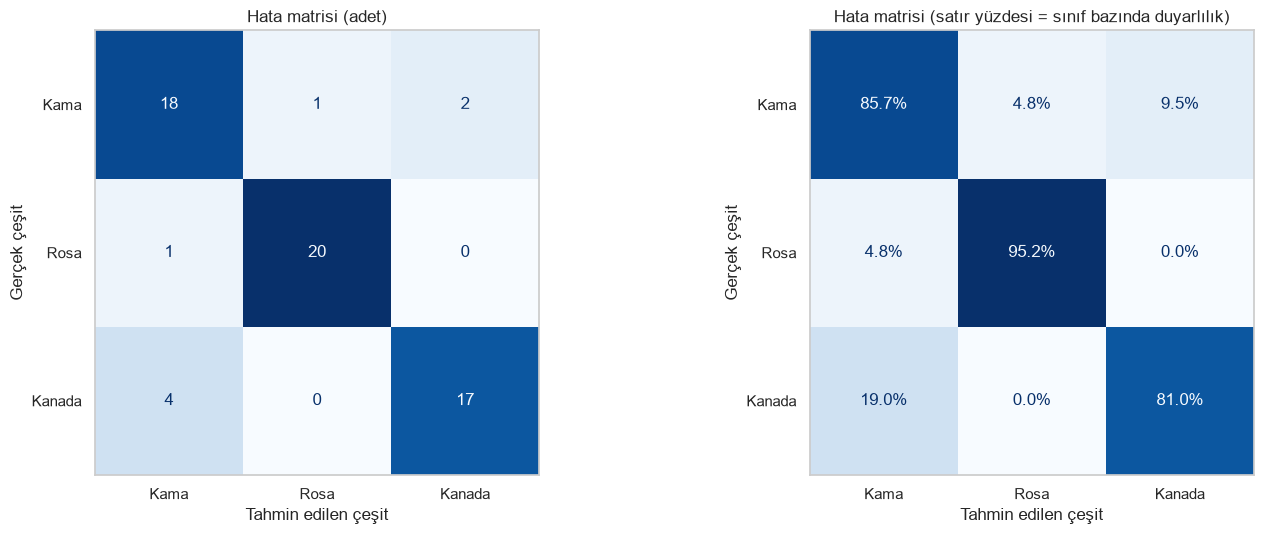

,Tahmin: Kama,Tahmin: Rosa,Tahmin: Kanada
Gerçek: Kama,18,1,2
Gerçek: Rosa,1,20,0
Gerçek: Kanada,4,0,17


In [21]:
cm = confusion_matrix(y_test, y_tahmin, labels=SINIFLAR)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ConfusionMatrixDisplay(cm, display_labels=SINIFLAR).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Hata matrisi (adet)")
ConfusionMatrixDisplay(cm / cm.sum(axis=1, keepdims=True), display_labels=SINIFLAR).plot(
    ax=axes[1], cmap="Blues", colorbar=False, values_format=".1%")
axes[1].set_title("Hata matrisi (satır yüzdesi = sınıf bazında duyarlılık)")
for ax in axes:
    ax.set_xlabel("Tahmin edilen çeşit")
    ax.set_ylabel("Gerçek çeşit")
    ax.grid(False)
plt.tight_layout()
plt.show()

pd.DataFrame(cm, index=[f"Gerçek: {s}" for s in SINIFLAR], columns=[f"Tahmin: {s}" for s in SINIFLAR])

In [22]:
satirlar = []
for i, s in enumerate(SINIFLAR):
    tp = cm[i, i]
    fn = cm[i].sum() - tp
    fp = cm[:, i].sum() - tp
    tn = cm.sum() - tp - fn - fp
    satirlar.append({"Sınıf": s, "TP": tp, "FN": fn, "FP": fp, "TN": tn})
display(pd.DataFrame(satirlar).set_index("Sınıf"))

hatalar = X_test[y_test != y_tahmin].copy()
hatalar.insert(0, "Gerçek", y_test[y_test != y_tahmin])
hatalar.insert(1, "Tahmin", y_tahmin[y_test != y_tahmin])
hatalar = hatalar.join(olasilik.add_prefix("P(").add_suffix(")"))
print("Yanlış sınıflandırılan test gözlemleri:")
hatalar

,TP,FN,FP,TN
Sınıf,,,,
Kama,18,3,5,37
Rosa,20,1,1,41
Kanada,17,4,2,40


Yanlış sınıflandırılan test gözlemleri:


,Gerçek,Tahmin,Alan,Cevre,Kompaktlik,TaneUzunlugu,TaneGenisligi,AsimetriKatsayisi,OlukUzunlugu,P(Kama),P(Rosa),P(Kanada)
63,Kama,Kanada,13.2200,13.8400,0.8680,5.3950,3.0700,4.1570,5.0880,0.4197,0.0279,0.5524
43,Kama,Rosa,15.5000,14.8600,0.8820,5.8770,3.3960,4.7110,5.5280,0.2834,0.6513,0.0653
201,Kanada,Kama,12.6700,13.3200,0.8977,4.9840,3.1350,2.3000,4.7450,0.9627,0.0030,0.0343
199,Kanada,Kama,12.7600,13.3800,0.8964,5.0730,3.1550,2.8280,4.8300,0.9393,0.0046,0.0561
52,Kama,Kanada,14.4900,14.6100,0.8538,5.7150,3.1130,4.1160,5.3960,0.3892,0.1924,0.4184
124,Rosa,Kama,15.9900,14.8900,0.9064,5.3630,3.5820,3.3360,5.1440,0.9167,0.0749,0.0083
165,Kanada,Kama,12.1000,13.1500,0.8793,5.1050,2.9410,2.2010,5.0560,0.8286,0.0055,0.1659
179,Kanada,Kama,12.2100,13.4700,0.8453,5.3570,2.8930,1.6610,5.1780,0.7317,0.0077,0.2606


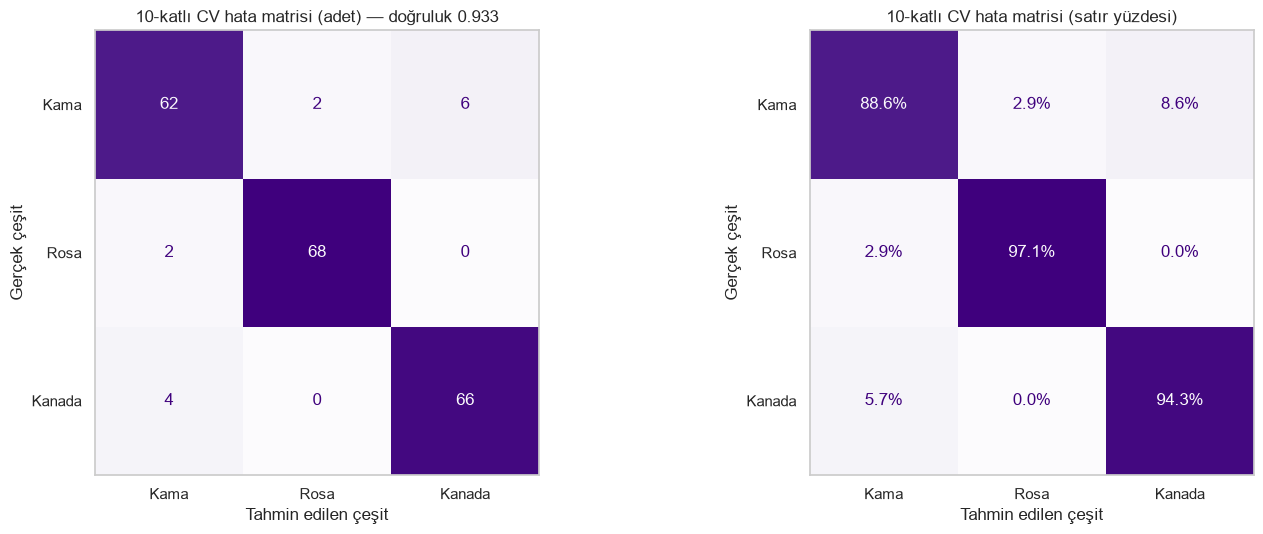

In [23]:
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=0)
y_cv = cross_val_predict(model, X, y, cv=cv10, n_jobs=-1)
cm_cv = confusion_matrix(y, y_cv, labels=SINIFLAR)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ConfusionMatrixDisplay(cm_cv, display_labels=SINIFLAR).plot(ax=axes[0], cmap="Purples", colorbar=False)
axes[0].set_title(f"10-katlı CV hata matrisi (adet) — doğruluk {accuracy_score(y, y_cv):.3f}")
ConfusionMatrixDisplay(cm_cv / cm_cv.sum(axis=1, keepdims=True), display_labels=SINIFLAR).plot(
    ax=axes[1], cmap="Purples", colorbar=False, values_format=".1%")
axes[1].set_title("10-katlı CV hata matrisi (satır yüzdesi)")
for ax in axes:
    ax.set_xlabel("Tahmin edilen çeşit")
    ax.set_ylabel("Gerçek çeşit")
    ax.grid(False)
plt.tight_layout()
plt.show()

In [24]:
print(classification_report(y_test, y_tahmin, labels=SINIFLAR, digits=4))
rapor = pd.DataFrame(classification_report(y_test, y_tahmin, labels=SINIFLAR, output_dict=True)).T
rapor = rapor.rename(columns={"precision": "Kesinlik", "recall": "Duyarlılık", "f1-score": "F1", "support": "Destek"},
                     index={"accuracy": "Doğruluk", "macro avg": "Makro ort.", "weighted avg": "Ağırlıklı ort."})
rapor.loc["Doğruluk", ["Kesinlik", "Duyarlılık", "Destek"]] = [np.nan, np.nan, len(y_test)]
rapor

              precision    recall  f1-score   support

        Kama     0.7826    0.8571    0.8182        21
        Rosa     0.9524    0.9524    0.9524        21
      Kanada     0.8947    0.8095    0.8500        21

    accuracy                         0.8730        63
   macro avg     0.8766    0.8730    0.8735        63
weighted avg     0.8766    0.8730    0.8735        63



,Kesinlik,Duyarlılık,F1,Destek
Kama,0.7826,0.8571,0.8182,21.0000
Rosa,0.9524,0.9524,0.9524,21.0000
Kanada,0.8947,0.8095,0.8500,21.0000
Doğruluk,NaN,NaN,0.8730,63.0000
Makro ort.,0.8766,0.8730,0.8735,63.0000
Ağırlıklı ort.,0.8766,0.8730,0.8735,63.0000


In [25]:
P_test = olasilik.values
Y_bin = label_binarize(y_test, classes=SINIFLAR)
ek = {
    "Doğruluk": accuracy_score(y_test, y_tahmin),
    "Makro F1": f1_score(y_test, y_tahmin, average="macro"),
    "Cohen kappa": cohen_kappa_score(y_test, y_tahmin),
    "Matthews korelasyon (MCC)": matthews_corrcoef(y_test, y_tahmin),
    "Makro ROC-AUC (OvR)": roc_auc_score(Y_bin, P_test, average="macro"),
    "Log-kayıp (çapraz entropi)": log_loss(y_test, model.predict_proba(X_test), labels=ann.classes_),
    "Ortalama tahmin güveni (maks. olasılık)": P_test.max(axis=1).mean(),
}
pd.Series(ek, name="Değer").to_frame()

,Değer
Doğruluk,0.8730
Makro F1,0.8735
Cohen kappa,0.8095
Matthews korelasyon (MCC),0.8108
Makro ROC-AUC (OvR),0.9637
Log-kayıp (çapraz entropi),0.3361
Ortalama tahmin güveni (maks. olasılık),0.8834


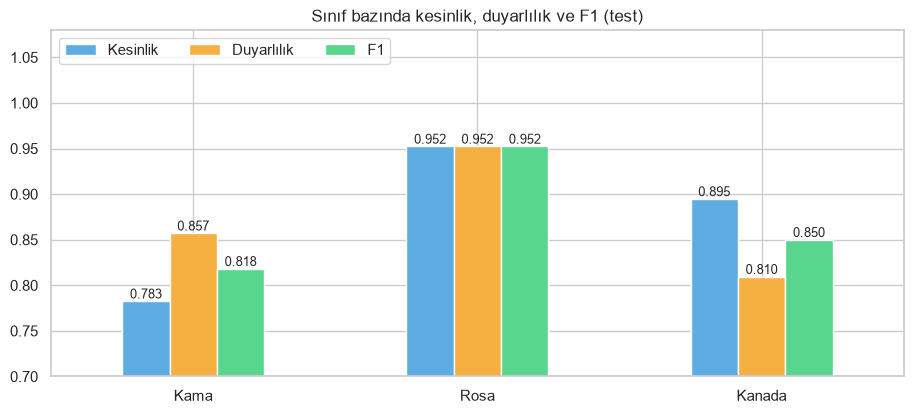

In [26]:
fig, ax = plt.subplots(figsize=(11, 4.5))
rapor.loc[SINIFLAR, ["Kesinlik", "Duyarlılık", "F1"]].plot.bar(ax=ax, rot=0, color=["#5DADE2", "#F5B041", "#58D68D"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=9)
ax.set_ylim(0.7, 1.08)
ax.set_title("Sınıf bazında kesinlik, duyarlılık ve F1 (test)")
ax.legend(loc="upper left", ncol=3)
plt.show()

,Test (nokta),Bootstrap %2.5,Bootstrap %97.5,Tekrarlı CV ort.,Tekrarlı CV std,Tekrarlı CV eğitim ort.
Doğruluk,0.8730,0.7778,0.9524,0.9262,0.0396,0.9552
Makro F1,0.8735,0.7820,0.9501,0.9255,0.0404,0.9552


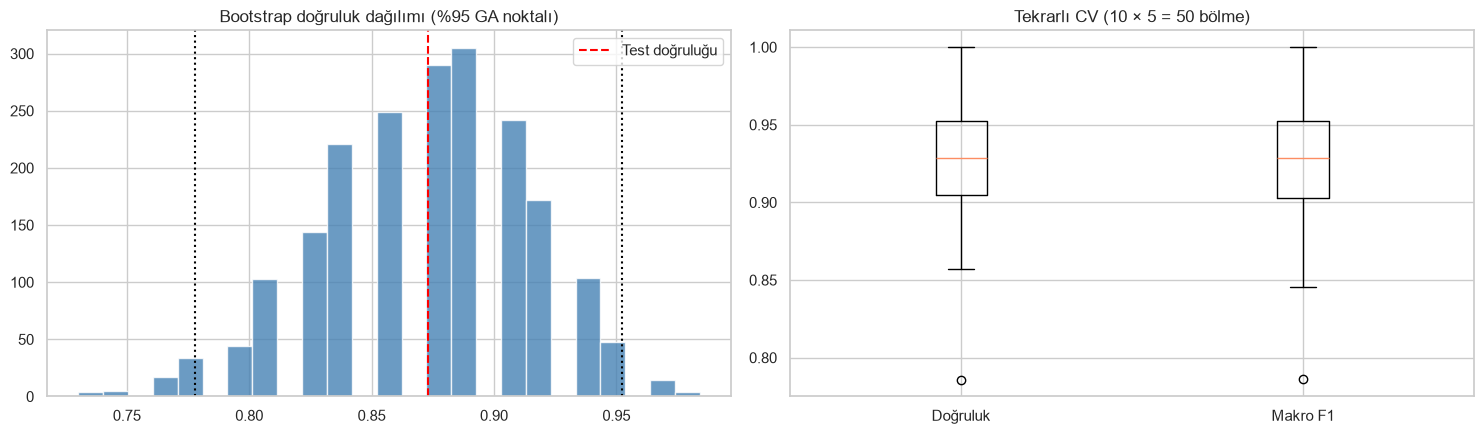

In [27]:
rng = np.random.default_rng(0)
yt, yp = y_test.to_numpy(), np.asarray(y_tahmin)
boot = []
for _ in range(2000):
    i = rng.integers(0, len(yt), len(yt))
    boot.append([accuracy_score(yt[i], yp[i]), f1_score(yt[i], yp[i], average="macro")])
boot = np.array(boot)

rcv = cross_validate(model, X, y, cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0),
                     scoring={"Doğruluk": "accuracy", "Makro F1": "f1_macro"}, n_jobs=-1, return_train_score=True)

display(pd.DataFrame({
    "Test (nokta)": [ek["Doğruluk"], ek["Makro F1"]],
    "Bootstrap %2.5": np.percentile(boot, 2.5, axis=0),
    "Bootstrap %97.5": np.percentile(boot, 97.5, axis=0),
    "Tekrarlı CV ort.": [rcv["test_Doğruluk"].mean(), rcv["test_Makro F1"].mean()],
    "Tekrarlı CV std": [rcv["test_Doğruluk"].std(), rcv["test_Makro F1"].std()],
    "Tekrarlı CV eğitim ort.": [rcv["train_Doğruluk"].mean(), rcv["train_Makro F1"].mean()],
}, index=["Doğruluk", "Makro F1"]))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].hist(boot[:, 0], bins=25, color="steelblue", alpha=0.8)
axes[0].axvline(ek["Doğruluk"], color="red", linestyle="--", label="Test doğruluğu")
for q in np.percentile(boot[:, 0], [2.5, 97.5]):
    axes[0].axvline(q, color="k", linestyle=":")
axes[0].set_title("Bootstrap doğruluk dağılımı (%95 GA noktalı)")
axes[0].legend()
axes[1].boxplot([rcv["test_Doğruluk"], rcv["test_Makro F1"]], tick_labels=["Doğruluk", "Makro F1"])
axes[1].set_title("Tekrarlı CV (10 × 5 = 50 bölme)")
plt.tight_layout()
plt.show()

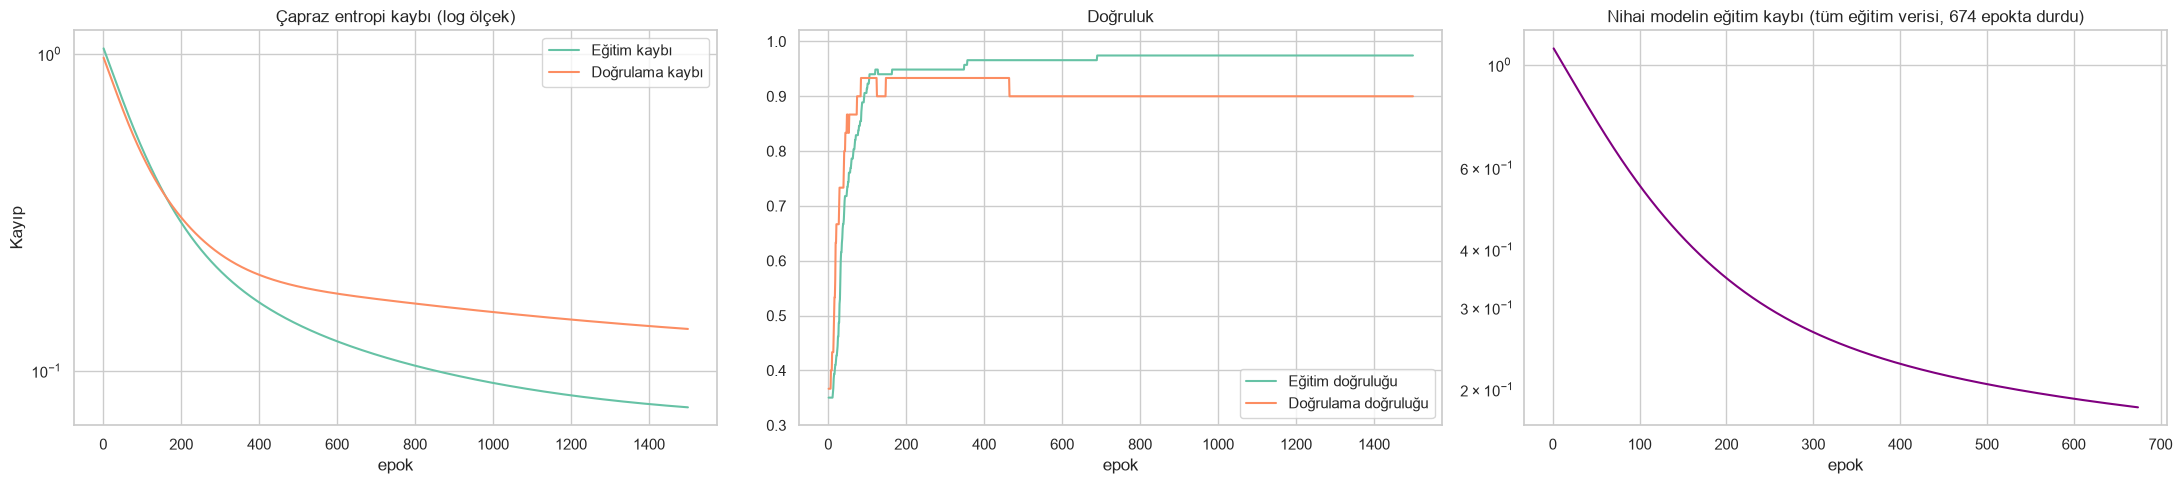

Doğrulama kaybının en düşük olduğu epok: 1500


,Eğitim kaybı,Doğrulama kaybı,Eğitim doğruluğu,Doğrulama doğruluğu
Epok,,,,
1,1.0409,0.9731,0.3504,0.3667
10,0.9716,0.9075,0.3504,0.4333
50,0.7140,0.6688,0.7350,0.8667
100,0.5029,0.4800,0.9145,0.9333
150,0.3742,0.3710,0.9402,0.9333
200,0.2938,0.3046,0.9487,0.9333
300,0.2067,0.2334,0.9487,0.9333
500,0.1398,0.1845,0.9658,0.9000
1000,0.0915,0.1531,0.9744,0.9000


In [28]:
X_ic, X_dog, y_ic, y_dog = train_test_split(X_egitim, y_egitim, test_size=0.2, stratify=y_egitim, random_state=1)
olc = StandardScaler().fit(X_ic)
Xi, Xd = olc.transform(X_ic), olc.transform(X_dog)
ag = MLPClassifier(**{k.replace("ann__", ""): v for k, v in arama.best_params_.items()}, solver="adam", random_state=42)
gecmis = []
for ep in range(1, 1501):
    ag.partial_fit(Xi, y_ic, classes=SINIFLAR)
    gecmis.append({"epok": ep, "Eğitim kaybı": log_loss(y_ic, ag.predict_proba(Xi), labels=ag.classes_),
                   "Doğrulama kaybı": log_loss(y_dog, ag.predict_proba(Xd), labels=ag.classes_),
                   "Eğitim doğruluğu": ag.score(Xi, y_ic), "Doğrulama doğruluğu": ag.score(Xd, y_dog)})
gecmis = pd.DataFrame(gecmis).set_index("epok")

fig, axes = plt.subplots(1, 3, figsize=(22, 5))
gecmis[["Eğitim kaybı", "Doğrulama kaybı"]].plot(ax=axes[0], logy=True)
axes[0].set_title("Çapraz entropi kaybı (log ölçek)")
axes[0].set_ylabel("Kayıp")
gecmis[["Eğitim doğruluğu", "Doğrulama doğruluğu"]].plot(ax=axes[1])
axes[1].set_ylim(0.3, 1.02)
axes[1].set_title("Doğruluk")
axes[2].plot(np.arange(1, ann.n_iter_ + 1), ann.loss_curve_, color="purple")
axes[2].set_yscale("log")
axes[2].set_xlabel("epok")
axes[2].set_title(f"Nihai modelin eğitim kaybı (tüm eğitim verisi, {ann.n_iter_} epokta durdu)")
for ax in axes[:2]:
    ax.set_xlabel("epok")
plt.tight_layout()
plt.show()

en_iyi_ep = gecmis["Doğrulama kaybı"].idxmin()
print(f"Doğrulama kaybının en düşük olduğu epok: {en_iyi_ep}")
gecmis.loc[sorted({1, 10, 50, 100, 150, 200, 300, 500, 1000, 1500, en_iyi_ep})].rename_axis("Epok")

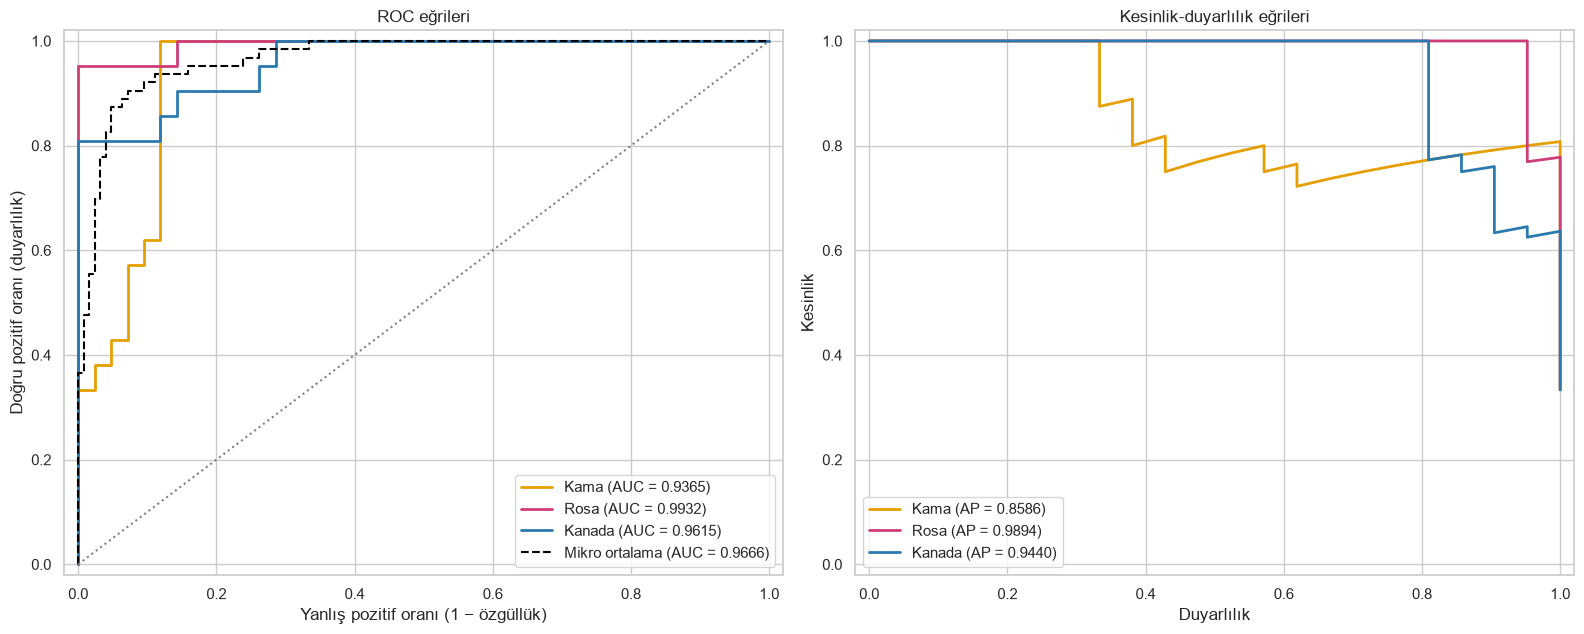

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for i, s in enumerate(SINIFLAR):
    fpr, tpr, _ = roc_curve(Y_bin[:, i], P_test[:, i])
    axes[0].plot(fpr, tpr, color=RENK[s], lw=2, label=f"{s} (AUC = {roc_auc_score(Y_bin[:, i], P_test[:, i]):.4f})")
    pr, rc, _ = precision_recall_curve(Y_bin[:, i], P_test[:, i])
    axes[1].plot(rc, pr, color=RENK[s], lw=2, label=f"{s} (AP = {average_precision_score(Y_bin[:, i], P_test[:, i]):.4f})")
fpr, tpr, _ = roc_curve(Y_bin.ravel(), P_test.ravel())
axes[0].plot(fpr, tpr, "k--", lw=1.5, label=f"Mikro ortalama (AUC = {roc_auc_score(Y_bin, P_test, average='micro'):.4f})")
axes[0].plot([0, 1], [0, 1], color="gray", linestyle=":")
axes[0].set_xlabel("Yanlış pozitif oranı (1 − özgüllük)")
axes[0].set_ylabel("Doğru pozitif oranı (duyarlılık)")
axes[0].set_title("ROC eğrileri")
axes[0].legend(loc="lower right")
axes[1].set_xlabel("Duyarlılık")
axes[1].set_ylabel("Kesinlik")
axes[1].set_title("Kesinlik-duyarlılık eğrileri")
axes[1].legend(loc="lower left")
for ax in axes:
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.02)
plt.tight_layout()
plt.show()

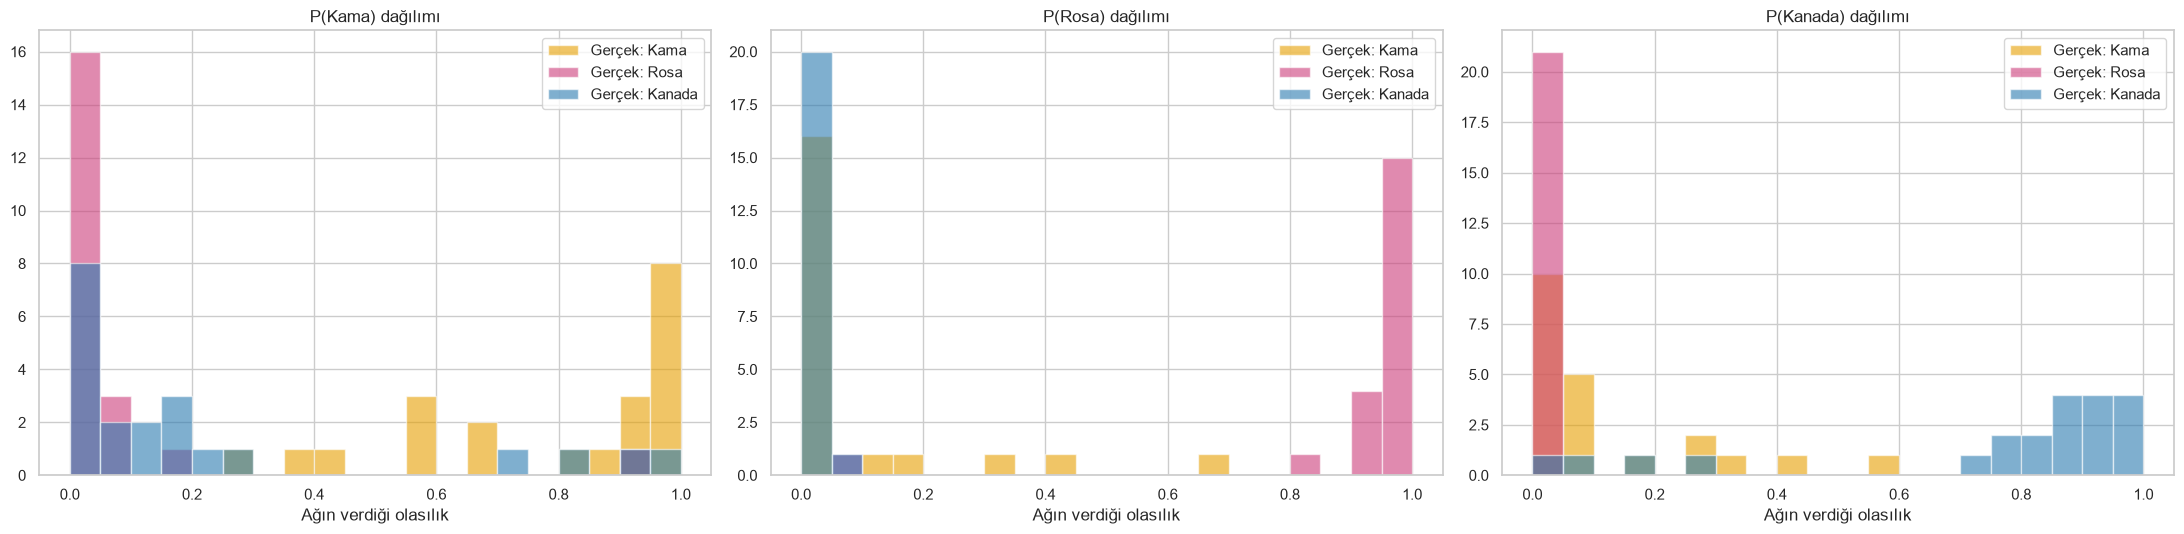

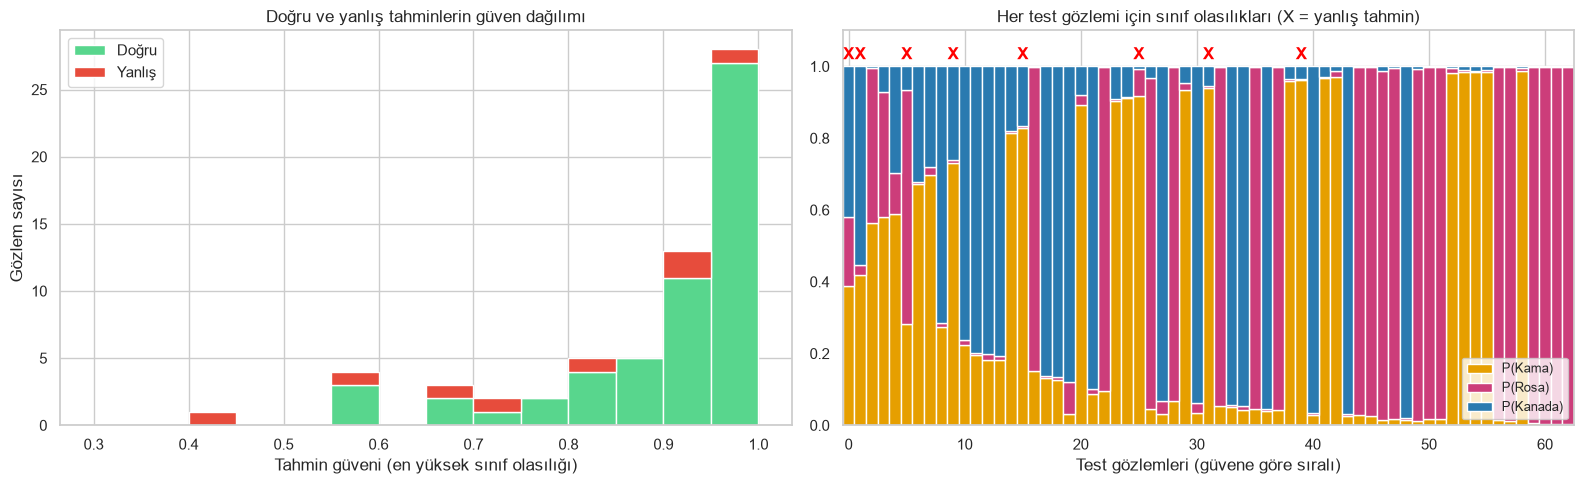

,Gözlem,Ortalama güven,Min güven
Doğru tahmin,55,0.9028,0.5641
Yanlış tahmin,8,0.7501,0.4184


In [30]:
dogru = (y_test.to_numpy() == y_tahmin)
fig, axes = plt.subplots(1, 3, figsize=(22, 5.5))
for i, s in enumerate(SINIFLAR):
    for g in SINIFLAR:
        axes[i].hist(olasilik.loc[y_test == g, s], bins=np.linspace(0, 1, 21), alpha=0.6, color=RENK[g],
                     label=f"Gerçek: {g}")
    axes[i].set_title(f"P({s}) dağılımı")
    axes[i].set_xlabel("Ağın verdiği olasılık")
    axes[i].legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
guven = P_test.max(axis=1)
axes[0].hist([guven[dogru], guven[~dogru]], bins=np.linspace(0.3, 1, 15), stacked=True,
             color=["#58D68D", "#E74C3C"], label=["Doğru", "Yanlış"])
axes[0].set_xlabel("Tahmin güveni (en yüksek sınıf olasılığı)")
axes[0].set_ylabel("Gözlem sayısı")
axes[0].set_title("Doğru ve yanlış tahminlerin güven dağılımı")
axes[0].legend()

sira = np.argsort(guven)
alt = np.zeros(len(sira))
for j, s in enumerate(SINIFLAR):
    axes[1].bar(np.arange(len(sira)), P_test[sira, j], bottom=alt, color=RENK[s], width=1.0, label=f"P({s})")
    alt += P_test[sira, j]
for k, idx in enumerate(sira):
    if not dogru[idx]:
        axes[1].annotate("X", (k, 1.02), ha="center", color="red", fontsize=12, fontweight="bold")
axes[1].set_xlim(-0.5, len(sira) - 0.5)
axes[1].set_ylim(0, 1.1)
axes[1].set_xlabel("Test gözlemleri (güvene göre sıralı)")
axes[1].set_title("Her test gözlemi için sınıf olasılıkları (X = yanlış tahmin)")
axes[1].legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

pd.DataFrame({"Gözlem": [dogru.sum(), (~dogru).sum()],
              "Ortalama güven": [guven[dogru].mean(), guven[~dogru].mean() if (~dogru).any() else np.nan],
              "Min güven": [guven[dogru].min(), guven[~dogru].min() if (~dogru).any() else np.nan]},
             index=["Doğru tahmin", "Yanlış tahmin"])

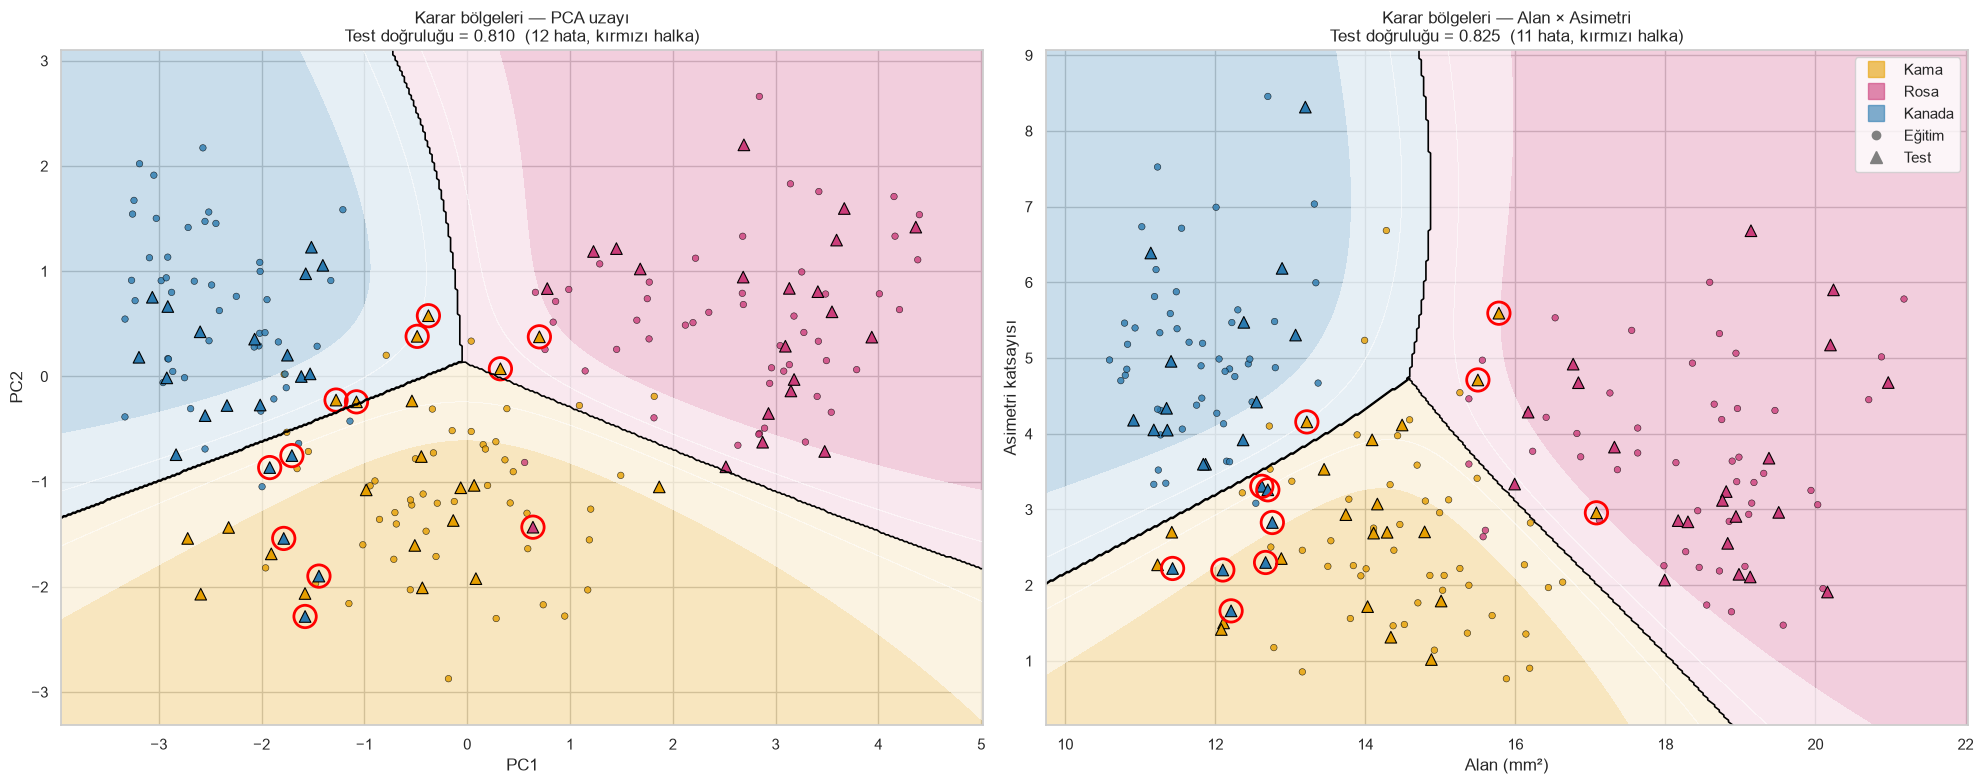

In [31]:
en_iyi = {k.replace("ann__", ""): v for k, v in arama.best_params_.items()}
CMAP = ListedColormap([RENK[s] for s in SINIFLAR])
kod = {s: i for i, s in enumerate(SINIFLAR)}

def sinir_ciz(ax, Xe, Xt, model2, baslik, xl, yl):
    x0, x1 = np.r_[Xe[:, 0], Xt[:, 0]].min(), np.r_[Xe[:, 0], Xt[:, 0]].max()
    y0, y1 = np.r_[Xe[:, 1], Xt[:, 1]].min(), np.r_[Xe[:, 1], Xt[:, 1]].max()
    px, py = (x1 - x0) * 0.08, (y1 - y0) * 0.08
    gx, gy = np.meshgrid(np.linspace(x0 - px, x1 + px, 400), np.linspace(y0 - py, y1 + py, 400))
    pr = model2.predict_proba(np.c_[gx.ravel(), gy.ravel()])
    sinif = np.array([kod[c] for c in model2.classes_])[pr.argmax(axis=1)].reshape(gx.shape)
    ax.contourf(gx, gy, sinif, levels=[-0.5, 0.5, 1.5, 2.5], cmap=CMAP, alpha=0.25)
    ax.contourf(gx, gy, pr.max(axis=1).reshape(gx.shape), levels=[0.0, 0.6, 0.8], colors=["white", "white"],
                alpha=0.55)
    ax.contour(gx, gy, sinif, levels=[0.5, 1.5], colors="k", linewidths=1.2)
    ye = np.array([kod[v] for v in y_egitim])
    yt_ = np.array([kod[v] for v in y_test])
    yp2 = np.array([kod[v] for v in model2.predict(Xt)])
    ax.scatter(Xe[:, 0], Xe[:, 1], c=ye, cmap=CMAP, vmin=0, vmax=2, s=22, edgecolor="k", linewidth=0.4, alpha=0.8)
    ax.scatter(Xt[:, 0], Xt[:, 1], c=yt_, cmap=CMAP, vmin=0, vmax=2, s=70, marker="^", edgecolor="k", linewidth=0.8)
    yanlis = yt_ != yp2
    ax.scatter(Xt[yanlis, 0], Xt[yanlis, 1], s=260, facecolor="none", edgecolor="red", linewidth=2)
    ax.set_title(f"{baslik}\nTest doğruluğu = {(~yanlis).mean():.3f}  ({yanlis.sum()} hata, kırmızı halka)")
    ax.set_xlabel(xl)
    ax.set_ylabel(yl)

olc2 = StandardScaler().fit(X_egitim)
pca2 = PCA(n_components=2).fit(olc2.transform(X_egitim))
Pe, Pt = pca2.transform(olc2.transform(X_egitim)), pca2.transform(olc2.transform(X_test))
ag_pca = Pipeline([("olcek", StandardScaler()), ("ann", MLPClassifier(**en_iyi, max_iter=3000, random_state=42))]).fit(Pe, y_egitim)

IKI = ["Alan", "AsimetriKatsayisi"]
ag_iki = Pipeline([("olcek", StandardScaler()), ("ann", MLPClassifier(**en_iyi, max_iter=3000, random_state=42))]
                  ).fit(X_egitim[IKI].to_numpy(), y_egitim)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
sinir_ciz(axes[0], Pe, Pt, ag_pca, "Karar bölgeleri — PCA uzayı", "PC1", "PC2")
sinir_ciz(axes[1], X_egitim[IKI].to_numpy(), X_test[IKI].to_numpy(), ag_iki, "Karar bölgeleri — Alan × Asimetri",
          "Alan (mm²)", "Asimetri katsayısı")
from matplotlib.lines import Line2D
el = [Line2D([], [], marker="s", linestyle="", color=RENK[s], markersize=12, alpha=0.6, label=s) for s in SINIFLAR] + \
     [Line2D([], [], marker="o", linestyle="", color="gray", label="Eğitim"),
      Line2D([], [], marker="^", linestyle="", color="gray", markersize=9, label="Test")]
axes[1].legend(handles=el, loc="upper right")
plt.tight_layout()
plt.show()

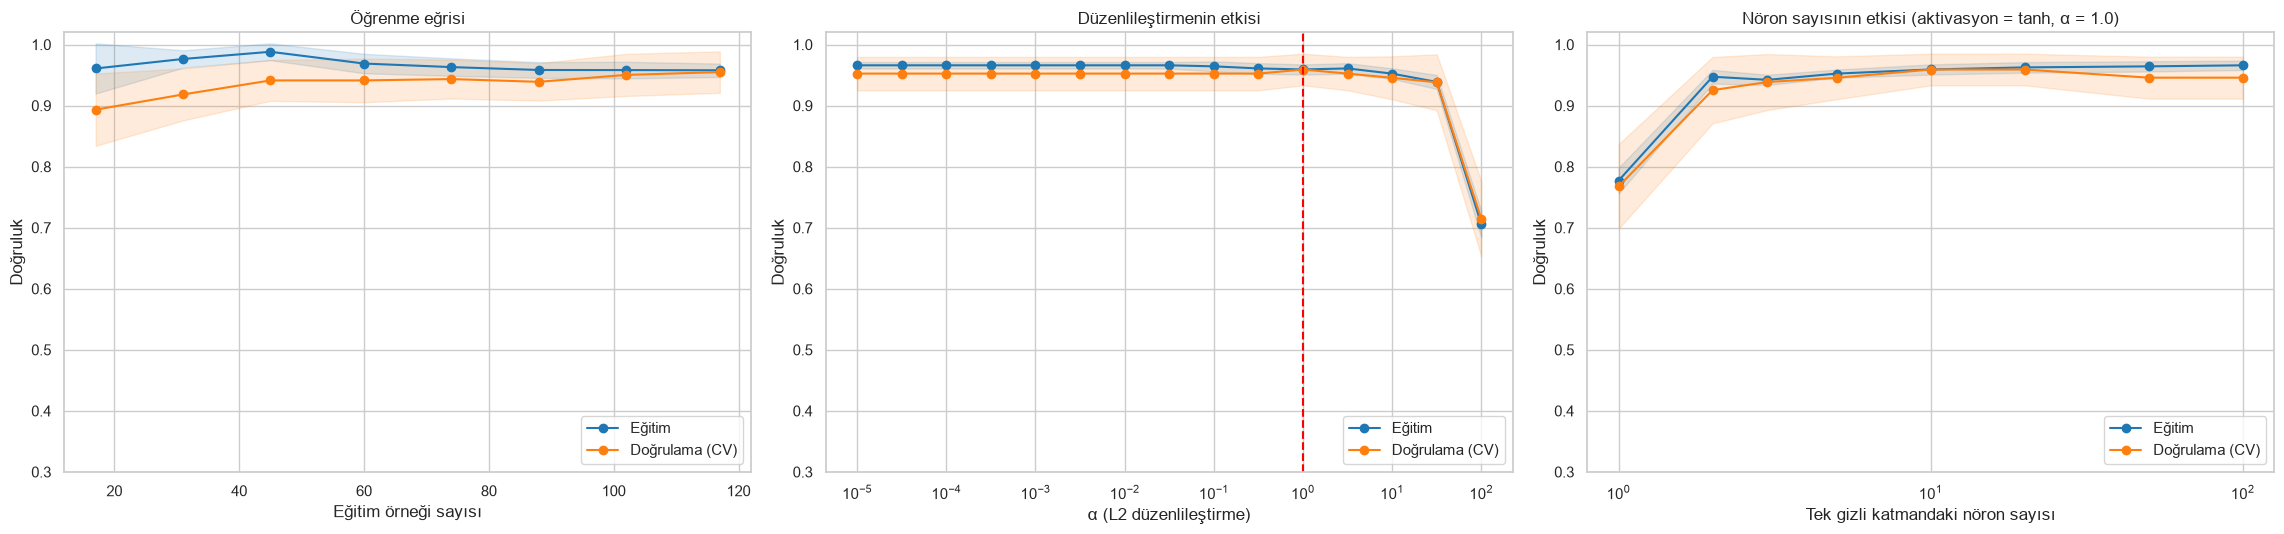

α,0.0000,0.0000,0.0001,0.0003,0.0010,0.0032,0.0100,0.0316,0.1000,0.3162,1.0000,3.1623,10.0000,31.6228,100.0000
Eğitim,0.9660,0.9660,0.9660,0.9660,0.9660,0.9660,0.9660,0.9660,0.9643,0.9609,0.9592,0.9609,0.9524,0.9387,0.7058
Doğrulama,0.9524,0.9524,0.9524,0.9524,0.9524,0.9524,0.9524,0.9524,0.9524,0.9524,0.9591,0.9524,0.9455,0.9382,0.7147


Nöron,1,2,3,5,10,20,50,100
Eğitim,0.7771,0.9473,0.9422,0.9524,0.9592,0.9626,0.9643,0.9660
Doğrulama,0.7676,0.9253,0.9386,0.9455,0.9591,0.9591,0.9457,0.9457


In [32]:
boyut, egt, dog = learning_curve(model, X_egitim, y_egitim, cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=0),
                                 train_sizes=np.linspace(0.15, 1.0, 8), scoring="accuracy", n_jobs=-1)

alfa_aralik = np.logspace(-5, 2, 15)
a_egt, a_dog = validation_curve(model, X_egitim, y_egitim, param_name="ann__alpha", param_range=alfa_aralik, cv=cv,
                                scoring="accuracy", n_jobs=-1)
noron = [1, 2, 3, 5, 10, 20, 50, 100]
n_egt, n_dog = validation_curve(model, X_egitim, y_egitim, param_name="ann__hidden_layer_sizes",
                                param_range=[(n,) for n in noron], cv=cv, scoring="accuracy", n_jobs=-1)

def bant(ax, x, e, d, logx=False):
    for a, r, ad in [(e, "tab:blue", "Eğitim"), (d, "tab:orange", "Doğrulama (CV)")]:
        ax.plot(x, a.mean(axis=1), "o-", color=r, label=ad)
        ax.fill_between(x, a.mean(axis=1) - a.std(axis=1), a.mean(axis=1) + a.std(axis=1), color=r, alpha=0.15)
    if logx:
        ax.set_xscale("log")
    ax.set_ylabel("Doğruluk")
    ax.legend(loc="lower right")

fig, axes = plt.subplots(1, 3, figsize=(23, 5.5))
bant(axes[0], boyut, egt, dog)
axes[0].set_xlabel("Eğitim örneği sayısı")
axes[0].set_title("Öğrenme eğrisi")
bant(axes[1], alfa_aralik, a_egt, a_dog, logx=True)
axes[1].axvline(ann.alpha, color="red", linestyle="--", label="Seçilen α")
axes[1].set_xlabel("α (L2 düzenlileştirme)")
axes[1].set_title("Düzenlileştirmenin etkisi")
bant(axes[2], noron, n_egt, n_dog, logx=True)
axes[2].set_xlabel("Tek gizli katmandaki nöron sayısı")
axes[2].set_title(f"Nöron sayısının etkisi (aktivasyon = {ann.activation}, α = {ann.alpha})")
for ax in axes:
    ax.set_ylim(0.3, 1.02)
plt.tight_layout()
plt.show()

display(pd.DataFrame({"Eğitim": a_egt.mean(axis=1), "Doğrulama": a_dog.mean(axis=1)}, index=alfa_aralik)
        .rename_axis("α").T)
pd.DataFrame({"Eğitim": n_egt.mean(axis=1), "Doğrulama": n_dog.mean(axis=1)}, index=noron).rename_axis("Nöron").T

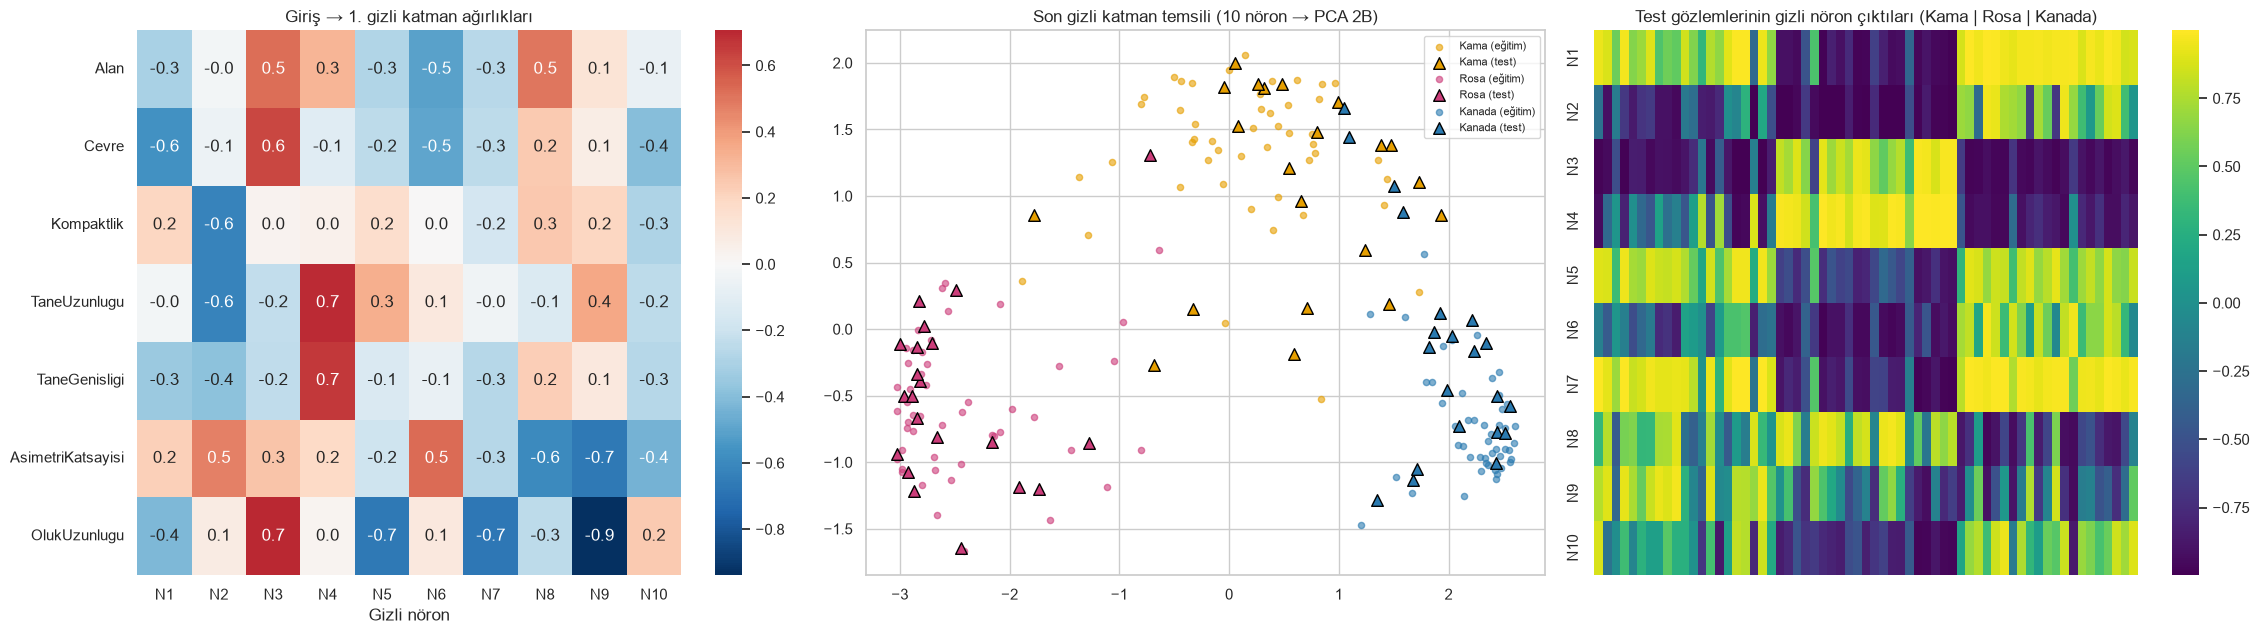

In [33]:
AKT = {"relu": lambda z: np.maximum(z, 0), "tanh": np.tanh, "logistic": lambda z: 1 / (1 + np.exp(-z)),
       "identity": lambda z: z}

def gizli_cikti(Xs, katman=-1):
    h = Xs
    n = len(ann.hidden_layer_sizes) if katman == -1 else katman + 1
    for W, b in zip(ann.coefs_[:n], ann.intercepts_[:n]):
        h = AKT[ann.activation](h @ W + b)
    return h

Xs_e = model.named_steps["olcek"].transform(X_egitim)
Xs_t = model.named_steps["olcek"].transform(X_test)
H_e, H_t = gizli_cikti(Xs_e), gizli_cikti(Xs_t)

fig = plt.figure(figsize=(23, 6.5))
ax0 = fig.add_subplot(1, 3, (1, 2)) if ann.coefs_[0].shape[1] > 12 else fig.add_subplot(1, 3, 1)
W0 = pd.DataFrame(ann.coefs_[0], index=OZELLIKLER, columns=[f"N{j+1}" for j in range(ann.coefs_[0].shape[1])])
sns.heatmap(W0, cmap="RdBu_r", center=0, ax=ax0, annot=W0.shape[1] <= 12, fmt=".1f")
ax0.set_title("Giriş → 1. gizli katman ağırlıkları")
ax0.set_xlabel("Gizli nöron")

ax1 = fig.add_subplot(1, 3, 3) if ann.coefs_[0].shape[1] > 12 else fig.add_subplot(1, 3, 2)
ph = PCA(n_components=2).fit(H_e)
for s in SINIFLAR:
    m = (y_egitim == s).to_numpy()
    q = ph.transform(H_e[m])
    ax1.scatter(q[:, 0], q[:, 1], s=20, color=RENK[s], alpha=0.6, label=f"{s} (eğitim)")
    m = (y_test == s).to_numpy()
    q = ph.transform(H_t[m])
    ax1.scatter(q[:, 0], q[:, 1], s=70, marker="^", color=RENK[s], edgecolor="k", label=f"{s} (test)")
ax1.set_title(f"Son gizli katman temsili ({H_e.shape[1]} nöron → PCA 2B)")
ax1.legend(fontsize=8)
if ann.coefs_[0].shape[1] <= 12:
    ax2 = fig.add_subplot(1, 3, 3)
    sns.heatmap(pd.DataFrame(H_t, columns=[f"N{j+1}" for j in range(H_t.shape[1])])
                .assign(_s=y_test.map(kod).to_numpy()).sort_values("_s").drop(columns="_s").T,
                cmap="viridis", ax=ax2, xticklabels=False)
    ax2.set_title("Test gözlemlerinin gizli nöron çıktıları (Kama | Rosa | Kanada)")
plt.tight_layout()
plt.show()

print(f"Son gizli katmanda hiç aktive olmayan (tüm eğitim verisinde 0) nöron sayısı: {(H_e.max(axis=0) == 0).sum()}"
      if ann.activation == "relu" else "")

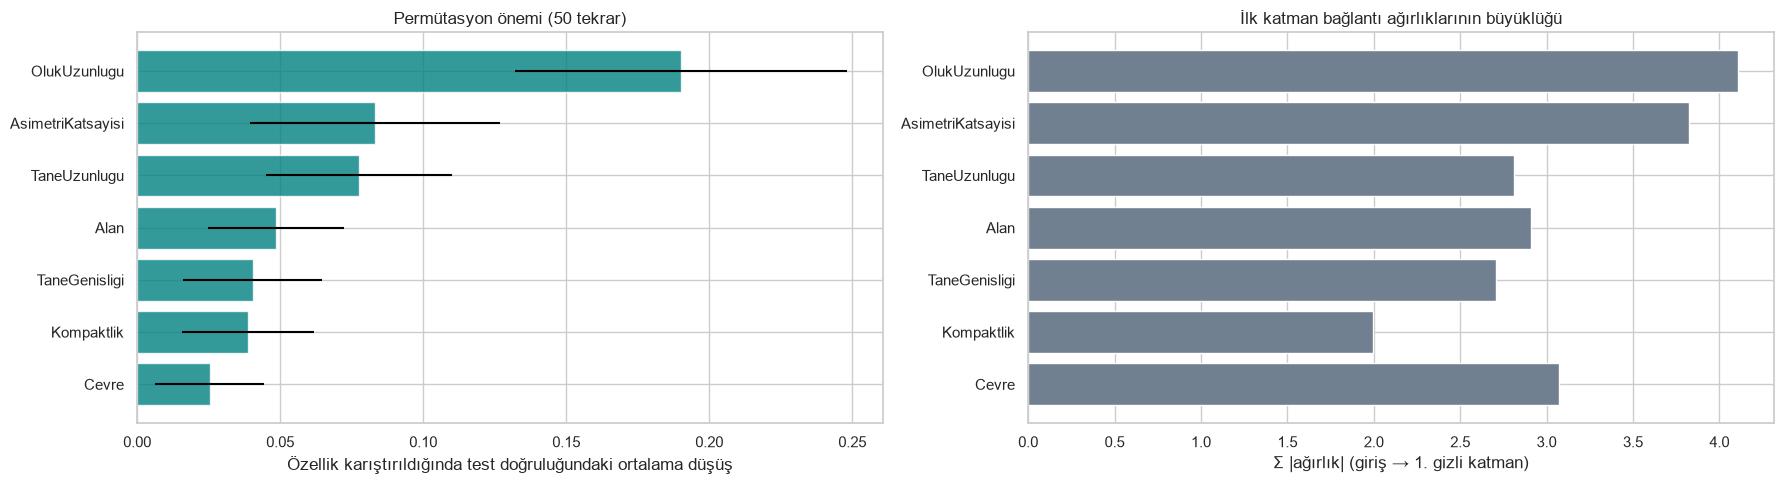

,Ortalama doğruluk düşüşü,Std,η² (EDA)
OlukUzunlugu,0.1902,0.0581,0.7809
AsimetriKatsayisi,0.0832,0.0438,0.3339
TaneUzunlugu,0.0775,0.0325,0.7569
Alan,0.0486,0.0238,0.8412
TaneGenisligi,0.0403,0.0244,0.7970
Kompaktlik,0.0387,0.0229,0.4230
Cevre,0.0254,0.0190,0.8396


In [34]:
pi = permutation_importance(model, X_test, y_test, n_repeats=50, random_state=0, scoring="accuracy", n_jobs=-1)
onem = pd.DataFrame({"Ortalama doğruluk düşüşü": pi.importances_mean, "Std": pi.importances_std,
                     "η² (EDA)": ayirt.loc[OZELLIKLER, "η²"].values}, index=OZELLIKLER) \
         .sort_values("Ortalama doğruluk düşüşü")

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
axes[0].barh(onem.index, onem["Ortalama doğruluk düşüşü"], xerr=onem["Std"], color="teal", alpha=0.8)
axes[0].set_xlabel("Özellik karıştırıldığında test doğruluğundaki ortalama düşüş")
axes[0].set_title("Permütasyon önemi (50 tekrar)")
grad = pd.Series(np.abs(ann.coefs_[0]).sum(axis=1), index=OZELLIKLER).loc[onem.index]
axes[1].barh(grad.index, grad.values, color="slategray")
axes[1].set_xlabel("Σ |ağırlık| (giriş → 1. gizli katman)")
axes[1].set_title("İlk katman bağlantı ağırlıklarının büyüklüğü")
plt.tight_layout()
plt.show()
onem.sort_values("Ortalama doğruluk düşüşü", ascending=False)

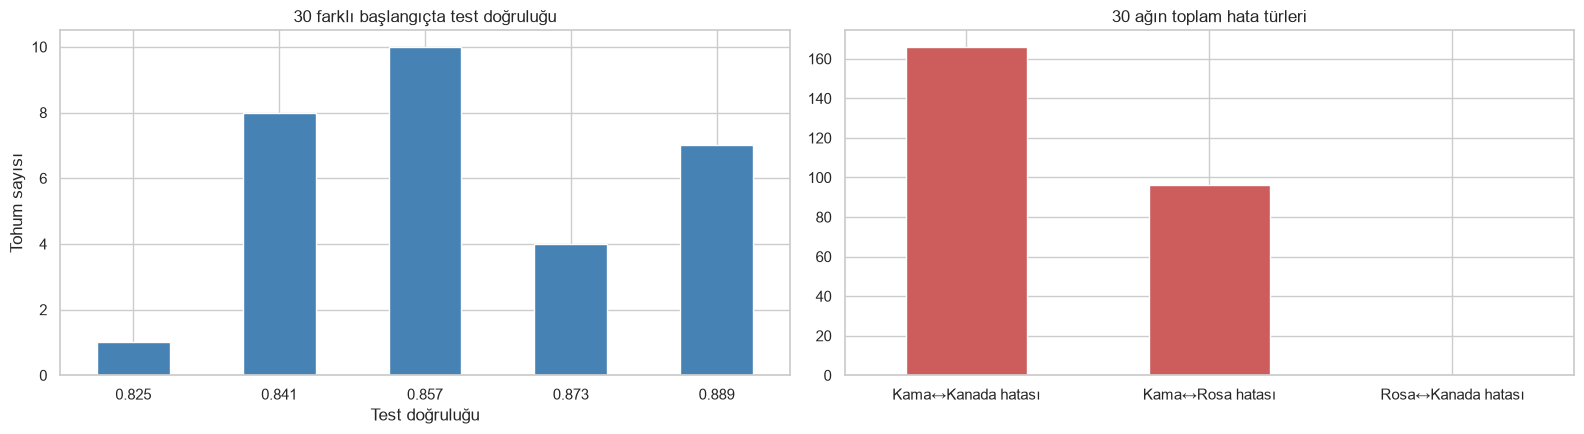

Kama↔Kanada hatası    166
Kama↔Rosa hatası       96
Rosa↔Kanada hatası      0


,count,mean,std,min,25%,50%,75%,max
Test doğruluğu,30.0000,0.8614,0.0191,0.8254,0.8413,0.8571,0.8730,0.8889
Makro F1,30.0000,0.8612,0.0197,0.8234,0.8404,0.8572,0.8735,0.8898
Epok,30.0000,707.5000,80.5454,562.0000,651.7500,703.5000,758.5000,851.0000


In [35]:
tohum = []
for t in range(30):
    m = Pipeline([("olcek", StandardScaler()), ("ann", MLPClassifier(**en_iyi, max_iter=3000, random_state=t))])
    m.fit(X_egitim, y_egitim)
    p = m.predict(X_test)
    tohum.append({"tohum": t, "Test doğruluğu": accuracy_score(y_test, p), "Makro F1": f1_score(y_test, p, average="macro"),
                  "Epok": m.named_steps["ann"].n_iter_,
                  "Kama↔Kanada hatası": int(((y_test == "Kama") & (p == "Kanada")).sum() + ((y_test == "Kanada") & (p == "Kama")).sum()),
                  "Kama↔Rosa hatası": int(((y_test == "Kama") & (p == "Rosa")).sum() + ((y_test == "Rosa") & (p == "Kama")).sum()),
                  "Rosa↔Kanada hatası": int(((y_test == "Rosa") & (p == "Kanada")).sum() + ((y_test == "Kanada") & (p == "Rosa")).sum())})
tohum = pd.DataFrame(tohum)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
tohum["Test doğruluğu"].value_counts().sort_index().plot.bar(ax=axes[0], color="steelblue", rot=0)
axes[0].set_xticklabels([f"{float(t.get_text()):.3f}" for t in axes[0].get_xticklabels()])
axes[0].set_xlabel("Test doğruluğu")
axes[0].set_ylabel("Tohum sayısı")
axes[0].set_title("30 farklı başlangıçta test doğruluğu")
tohum[["Kama↔Kanada hatası", "Kama↔Rosa hatası", "Rosa↔Kanada hatası"]].sum().plot.bar(ax=axes[1], rot=0, color="indianred")
axes[1].set_title("30 ağın toplam hata türleri")
plt.tight_layout()
plt.show()
print(tohum[["Kama↔Kanada hatası", "Kama↔Rosa hatası", "Rosa↔Kanada hatası"]].sum().to_string())
tohum[["Test doğruluğu", "Makro F1", "Epok"]].describe().T